In [41]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Device selection

In [42]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

# Auxiliary lattice plot

4 possible layouts


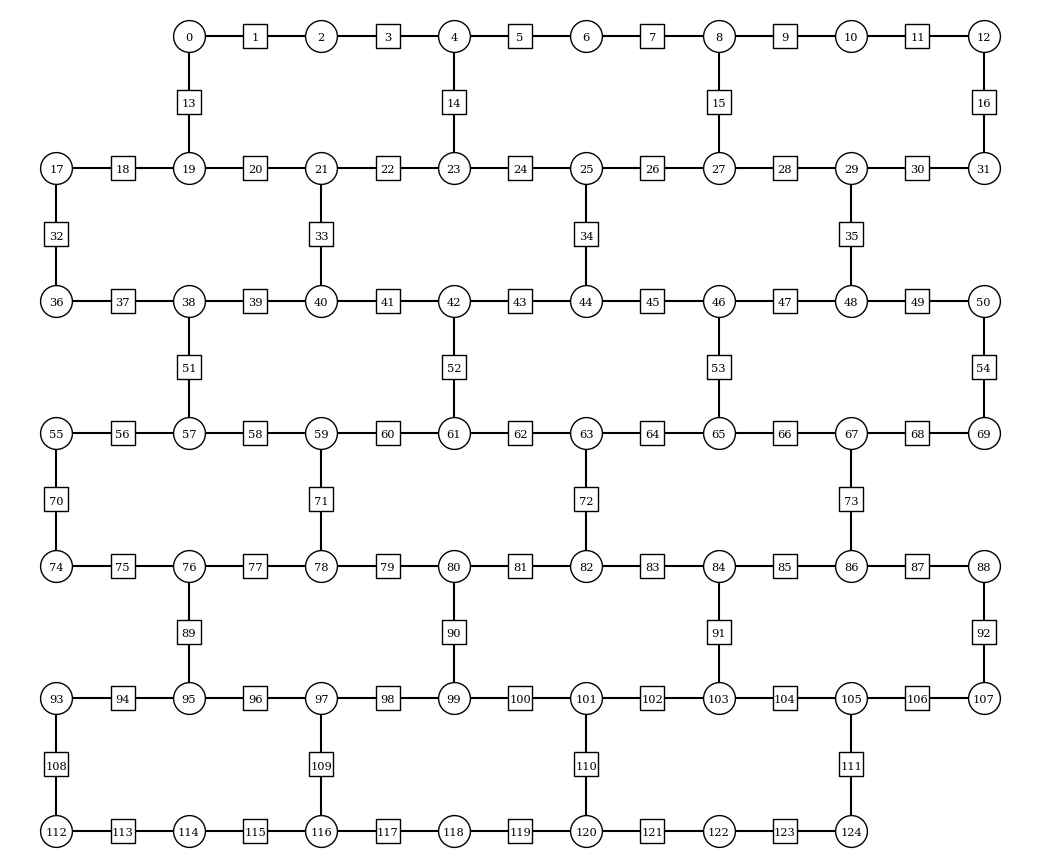

In [ ]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

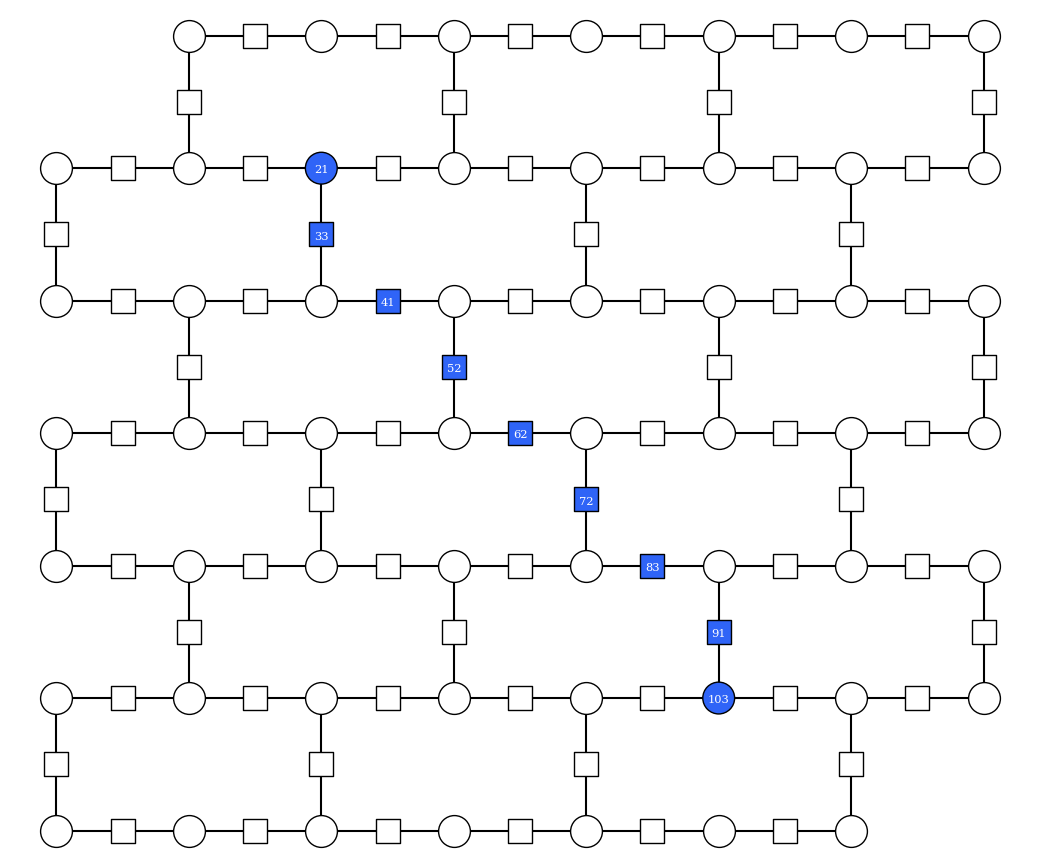

In [44]:
from z2hex.gdd import random, constant, counteract_rotation, from_matrix, zero_mean_gdd_matrix
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 5
h = 0.8
lamb = 1

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 71, 78]
string = [21, 33, 41, 52, 62, 72, 83, 91, 103]

final_time = 3
dt = 0.1
steps = 40
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 300000
confidence = 0.7

odr = True
postselect_odr = True
flip_threshold = 14
all_or_first_layout_qubit = True
forbidden_qubits = []
max_layouts = 5
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = partial(from_matrix, matrix=zero_mean_gdd_matrix(lattice, steps))

if callable(g_func):
    g_func.__name__ = from_matrix.__name__

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": True,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
}

execution_database = "z2_hex_jobs_postselection.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string))

# Error guarantees

In [45]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims)

error_dt = trotter_dt(desired_error, lattice, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"To guarantee the desired error, Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

To guarantee the desired error, Δt should be:
Δt = 0.01698
To correctly reach the desired final time, the number of layers required is:
N = 177 (1062 2Qb depth)


In [46]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims)

settings_error = trotter_error(dt, lattice,J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.10000
The error per layer commited in the wrost case is
Ɛ = 2.0425
The number of layers at the final evolution time is
N = 29 (174 2Qb depth)


# Circuit generation & observables

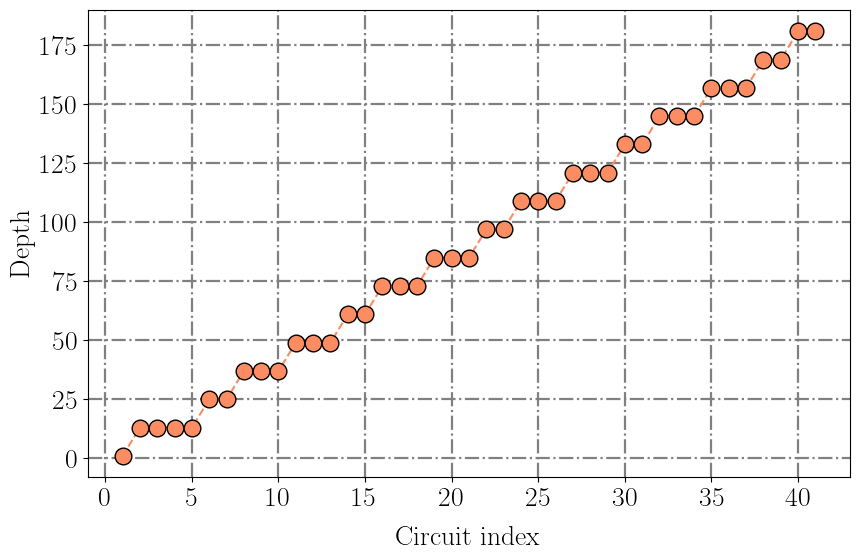

In [47]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, get_layouts
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
from z2hex.geometry import HeavyHexLattice
from functools import partial
from itertools import product
import numpy as np
import os

optimization_level = 3

lattice = HeavyHexLattice(*lattice_dims)

layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
if layouts.shape[0] > max_layouts:
    rand_idx = np.random.choice(layouts.shape[0], max_layouts, replace=False)
    layouts = layouts[rand_idx, :]
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, False)
circuits = string_quench_simulation_circuits_dt(*circs_args)
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit} | ({"fractional_gates": True} if fractional_gates else {})
if odr:
    circuits, odr_circuits = simulation_and_odr_circuits(*circs_args)
else:
    circuits = simulation_and_odr_circuits(*circs_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_x(lattice, i) if x_basis else local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis)

plot_circuit_arr_depth(circuits[0])

# Load jobs with the same options

In [48]:
from utils.postselection_multithreaded import load_postselected_jobs
import pickle
import os

overwrite = False
if curated_data_folder_path is not None:
    curated_data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
else:
    curated_data_filepath = ""

if overwrite or not os.path.exists(curated_data_filepath):
    if odr:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, odr_circuits=odr_circuits, postselect_odr=postselect_odr, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
    else:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = load_postselected_jobs(job_db, service, sampler_options, circuits, postselection_operators_func, observable_generating_funcs, extra_options=extra_options, recovery=recovery, flip_threshold=flip_threshold, jobs_result_folder=jobs_result_folder, confidence=confidence, return_samples_dicts=True, return_postselected_samples_dicts=True, return_layouts=True, verbose=True)
    if curated_data_filepath is not None:
        with open(curated_data_filepath, "wb") as f:
            pickle.dump((observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts), f)
else:
    with open(curated_data_filepath, "rb") as f:
        observables, observables_confidence, samples_dicts, postselected_samples_dicts, layouts = pickle.load(f)

Loaded 328 jobs                                                                                    


In [49]:
from utils.postselection_multithreaded import multiprocess_layouts_combine_samples_dicts

layout_combined_postselected_samples_dicts = multiprocess_layouts_combine_samples_dicts(postselected_samples_dicts[0])
total_samples = sum(layout_combined_postselected_samples_dicts[-1].values())
print(f"Total last step postselected samples: {total_samples}")

Total last step postselected samples: 61303


# Observable plots

## Single frame plots

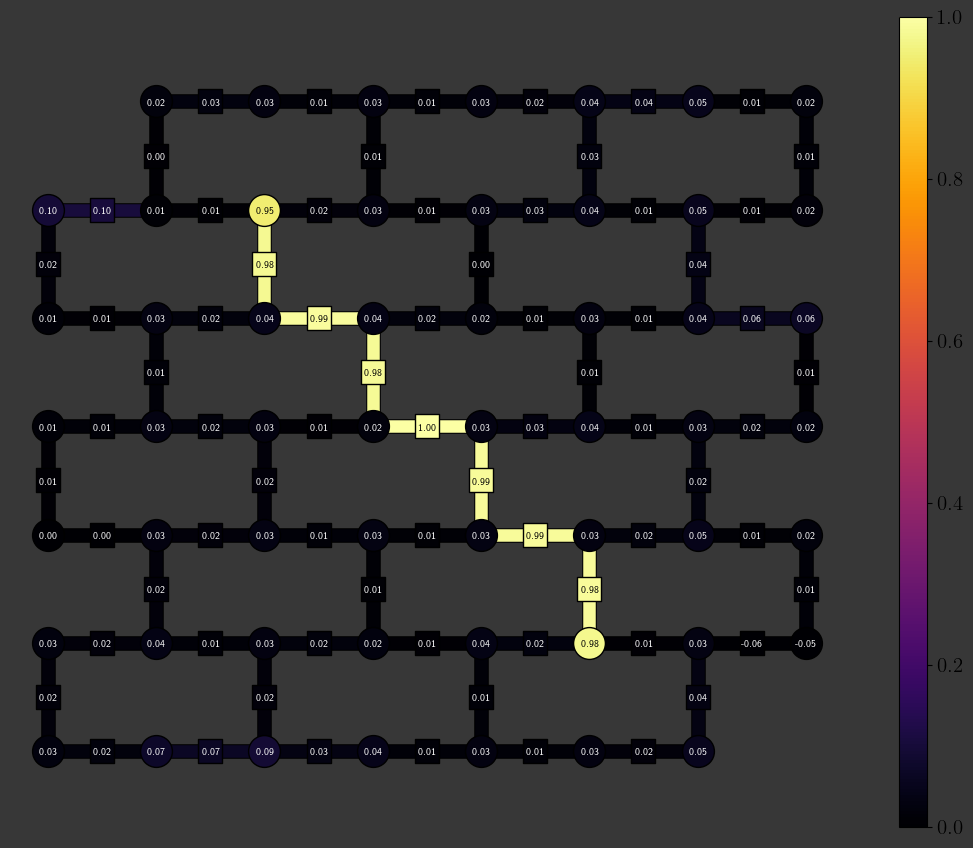

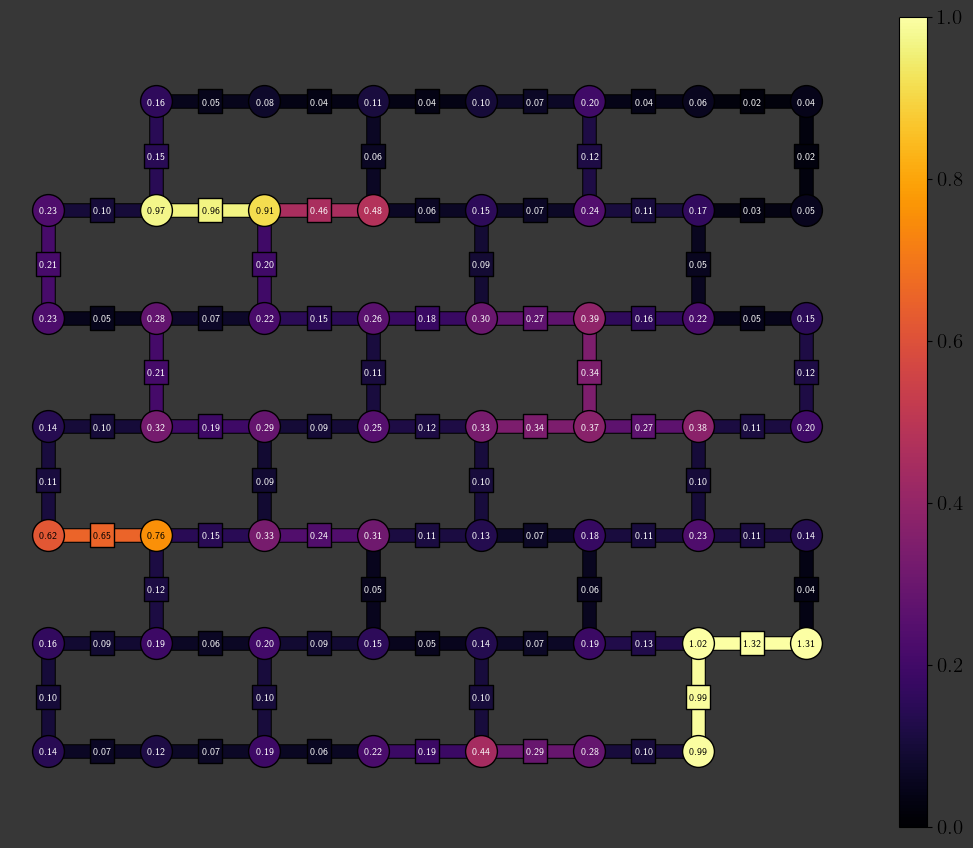

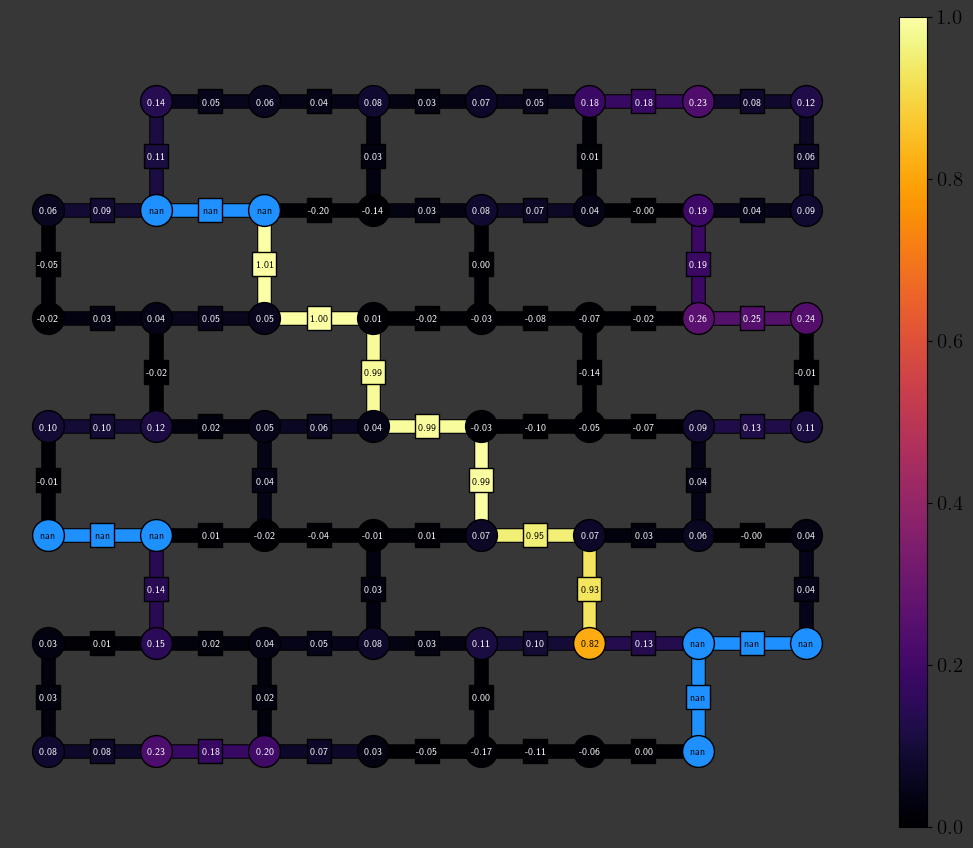

In [50]:
from utils.postselection import initialize_postselection, measure_diagonal_observables, get_recovered_postselected_samples_dict
from z2hex.plotting import local_observable_plot
import utils.odr as odr

job_index = 1

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

psamples = postselected_samples_dicts[0][0][job_index]
podrsamples = postselected_samples_dicts[1][0][job_index]
pobservables = measure_diagonal_observables(podrsamples, diagonal_observables, circuits[0][job_index].layout.final_index_layout())[::-1]
podrprob = odr.compute_depolarizing_probability(pobservables, 1, 0, odr_circuits[0][job_index].num_qubits)
finalobs = odr.renormalize_observable(observables[1][job_index], podrprob, 0, circuits[0][job_index].num_qubits, [-1, 1])

local_observable_plot((1-observables[0][job_index])/2, lattice, cmap_range=[0, 1], dark_theme=True)
local_observable_plot(podrprob, lattice, cmap_range=[0, 1], dark_theme=True)
local_observable_plot((1-finalobs)/2, lattice, cmap_range=[0, 1], dark_theme=True)

In [51]:
((1-observables[0][2])/2)[26]

0.03807159464558574

# Animation

In [52]:
from z2hex.plotting import local_obs_anim

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

postselected_odr_filepath = f"z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
postselected_filepath = f"z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
odr_filepath = f"z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
raw_filepath = f"z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
local_obs_anim((1-observables[0])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_odr_filepath)
local_obs_anim((1-observables[1])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=postselected_filepath)
local_obs_anim((1-observables[2])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=odr_filepath)
local_obs_anim((1-observables[3])/2, lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_range=[0, 1], dark_theme=True, filepath=raw_filepath)

ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 16.0.0 (clang-1600.0.26.4)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1_4 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --e

## String and transversals

### Single qubit plots

##### Gauge

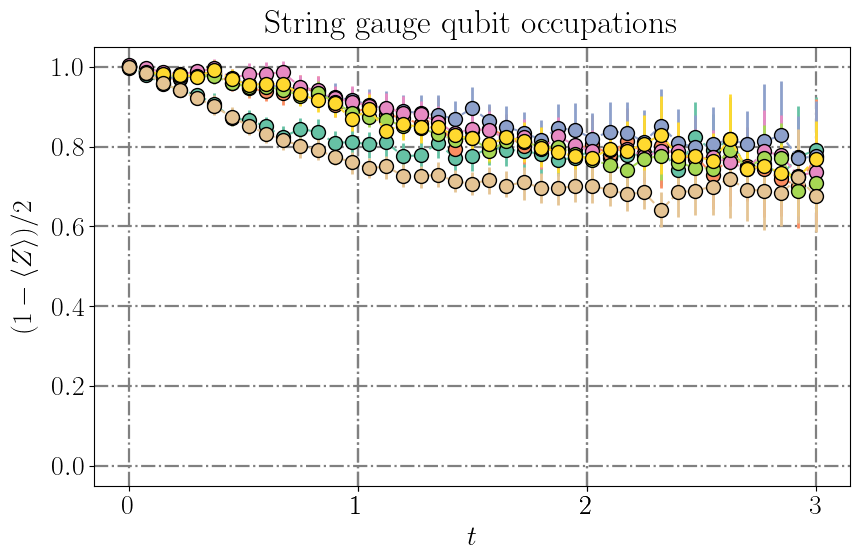

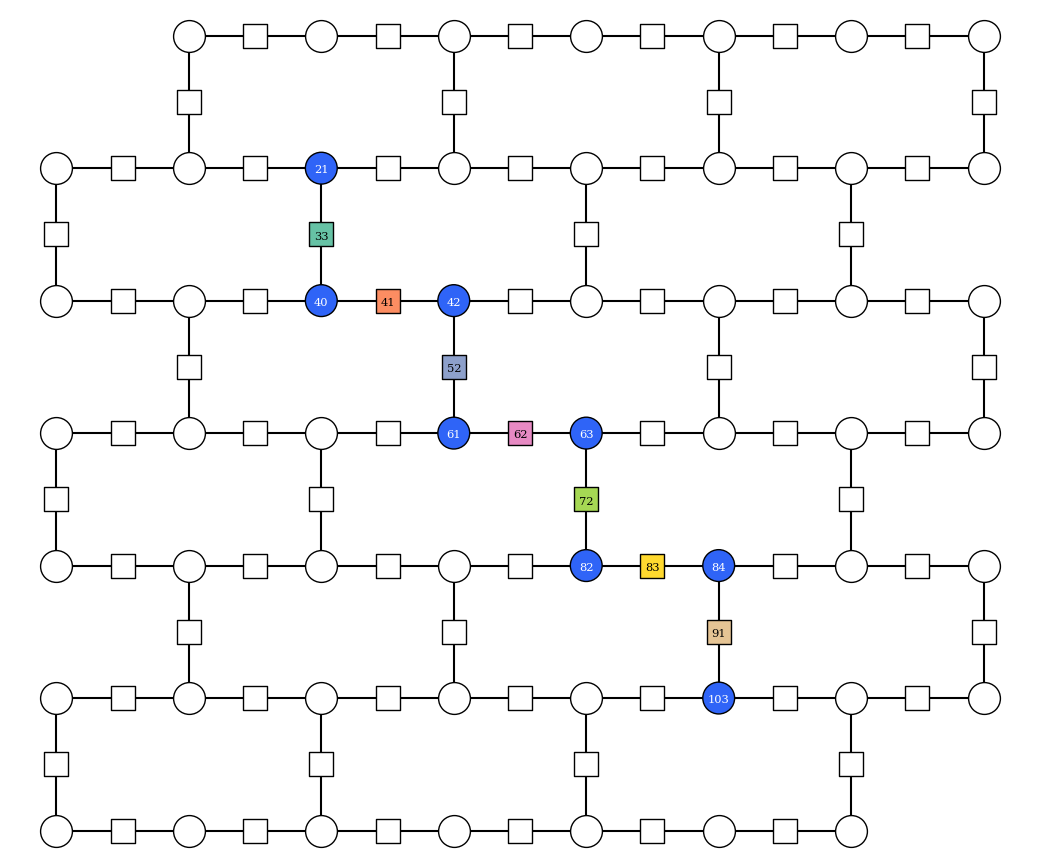

In [53]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "String gauge qubit occupations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
complete_string_qubit_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string_qubit_coords))
matter_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if not is_edge_coords(coords)]
gauge_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if is_edge_coords(coords)]
matter_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(matter_complete_string_qubit_coords)
gauge_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(gauge_complete_string_qubit_coords)

plot_filepath = f"z2hex_quench_longitudinal_string_gauge_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_longitudinal_string_gauge_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

stdm = (1 - observables_confidence[0][:, gauge_complete_string_qubit_qbinds, :])/2

plot_individual_qubits_observable_evolution((1 - observables[0][:, gauge_complete_string_qubit_qbinds])/2, observable_confidence_matrix=stdm, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(gauge_complete_string_qubit_qbinds + matter_complete_string_qubit_qbinds, colors=[cmap(i%8) for i in range(len(gauge_complete_string_qubit_qbinds))]+["#2f64f7"]*len(matter_complete_string_qubit_qbinds), filepath=legend_filepath)

##### Matter

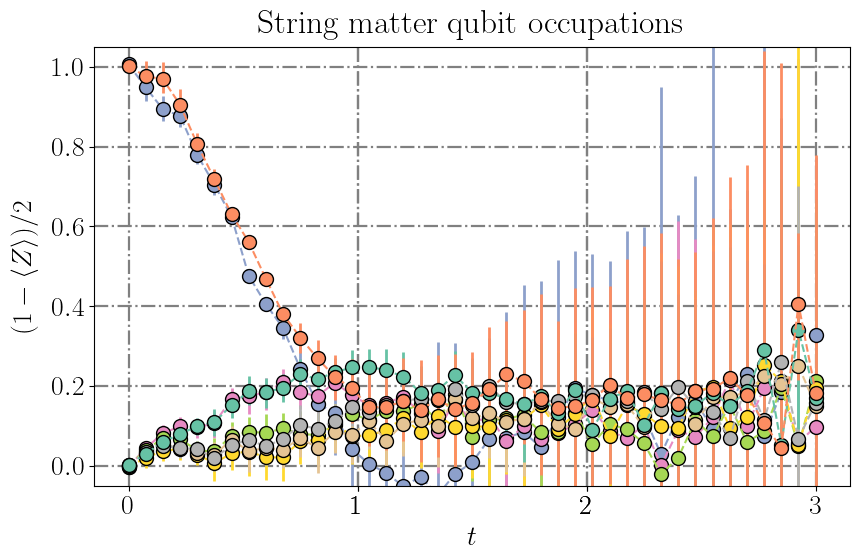

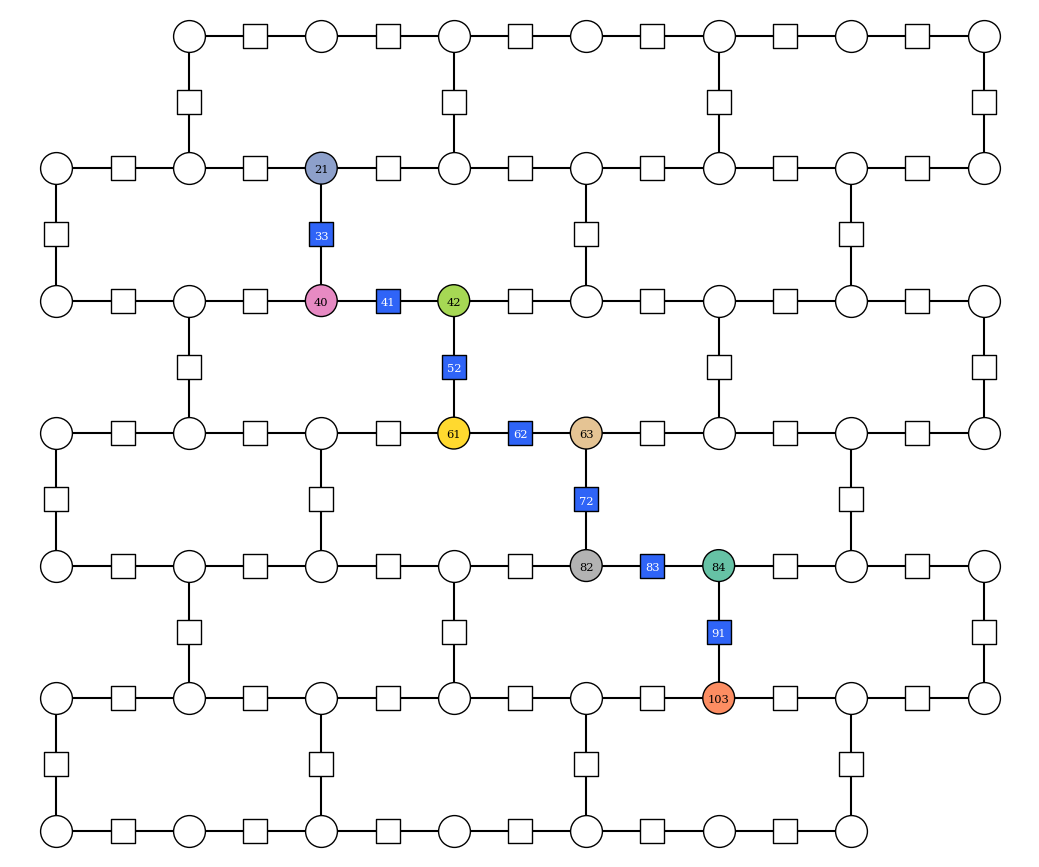

In [54]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")((x+2)%8)
markers = None #["v", "^"]
title = "String matter qubit occupations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
complete_string_qubit_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string_qubit_coords))
matter_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if not is_edge_coords(coords)]
gauge_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if is_edge_coords(coords)]
matter_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(matter_complete_string_qubit_coords)
gauge_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(gauge_complete_string_qubit_coords)

plot_filepath = f"z2hex_quench_longitudinal_string_matter_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_longitudinal_string_matter_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

stdm = (1 - observables_confidence[0][:, matter_complete_string_qubit_qbinds, :])/2

plot_individual_qubits_observable_evolution((1 - observables[0][:, matter_complete_string_qubit_qbinds])/2, observable_confidence_matrix=stdm, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(matter_complete_string_qubit_qbinds + gauge_complete_string_qubit_qbinds, colors=[cmap(i%8) for i in range(len(matter_complete_string_qubit_qbinds))] + ["#2f64f7"]*len(gauge_complete_string_qubit_qbinds), filepath=legend_filepath)

### Mean between qubits

##### Gauge & Matter

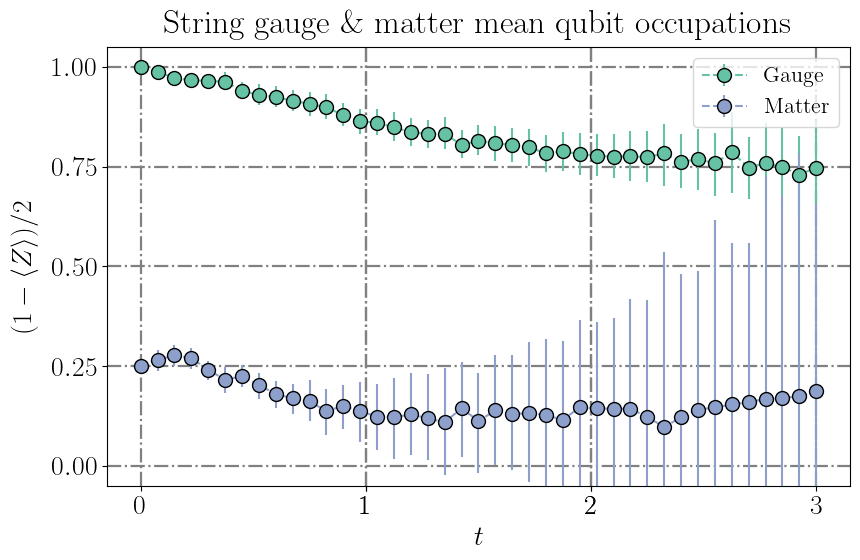

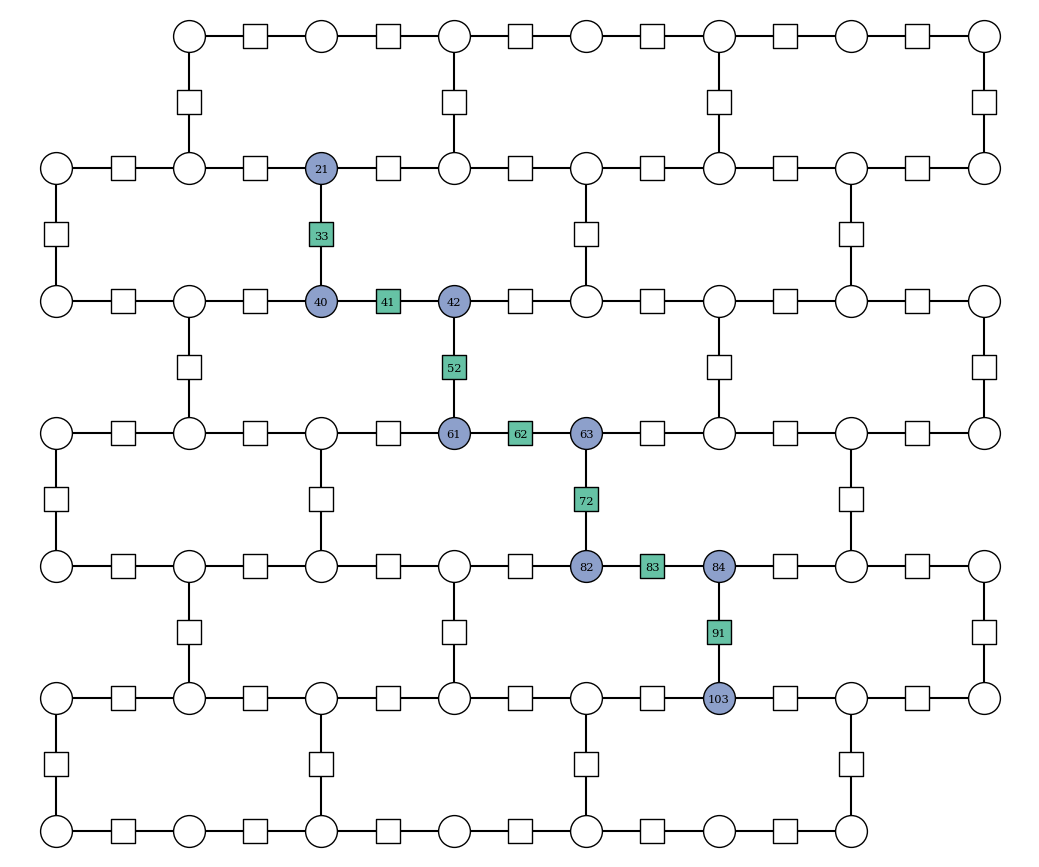

In [55]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(2*x)
markers = None #["v", "^"]
title = r"String gauge \& matter mean qubit occupations"
legend = True

string_qubit_coords = np.array(lattice.coords)[string]
complete_string_qubit_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string_qubit_coords))
matter_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if not is_edge_coords(coords)]
gauge_complete_string_qubit_coords = [coords for coords in complete_string_qubit_coords if is_edge_coords(coords)]
matter_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(matter_complete_string_qubit_coords)
gauge_complete_string_qubit_qbinds = lattice.coords_to_logical_qb(gauge_complete_string_qubit_coords)
qubits_to_average = [gauge_complete_string_qubit_qbinds, matter_complete_string_qubit_qbinds]

plot_filepath = f"z2hex_quench_longitudinal_string_gauge_mean_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_longitudinal_string_gauge_mean_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
labels = ["Gauge", "Matter"]

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_ticks=[0, 0.25, 0.5, 0.75, 1], y_lim=[-0.05, 1.05], markers=markers, title=title, funclabels=labels, legend=legend, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_average, colors=[cmap(i%8) for i in range(len(qubits_to_average))], join_lines=[False, False], filepath=legend_filepath) 

## String transversals

### Individual qubit plots

#### Gauge

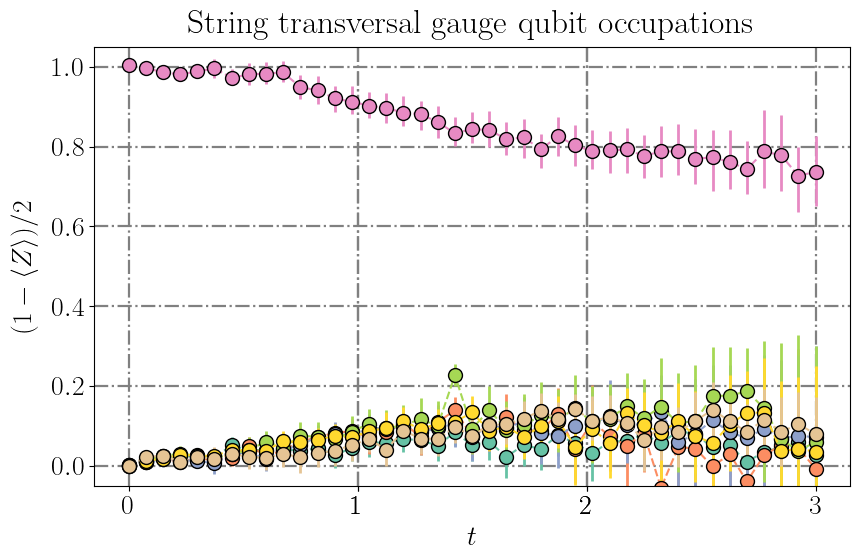

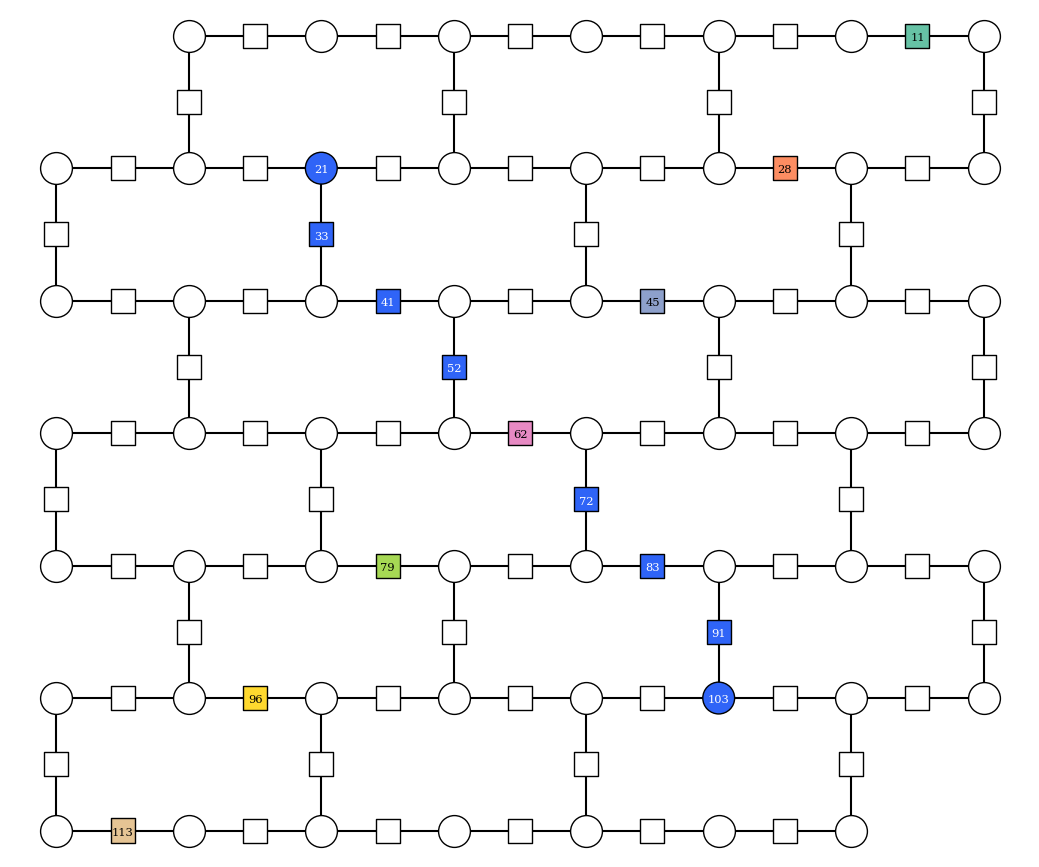

In [56]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x)
markers = None #["v", "^"]
title = "String transversal gauge qubit occupations"
legend = False

start_coords = lattice.coords[11]
angle = -1
transversal_gauge_qubits = lattice.line_of_qubits(lattice.coords_to_logical_qb(start_coords), angle)
sliced_observable = observables[0][:, transversal_gauge_qubits]
sliced_observable_confidence = observables_confidence[0][:, transversal_gauge_qubits]
clean_string = [qb for qb in string if qb not in transversal_gauge_qubits]

plot_filepath = f"z2hex_quench_transversal_string_gauge_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_transversal_string_gauge_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_individual_qubits_observable_evolution((1 - sliced_observable)/2, observable_confidence_matrix=(1-sliced_observable_confidence)/2, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(transversal_gauge_qubits + clean_string, colors=[cmap(i) for i in range(len(transversal_gauge_qubits))]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Matter

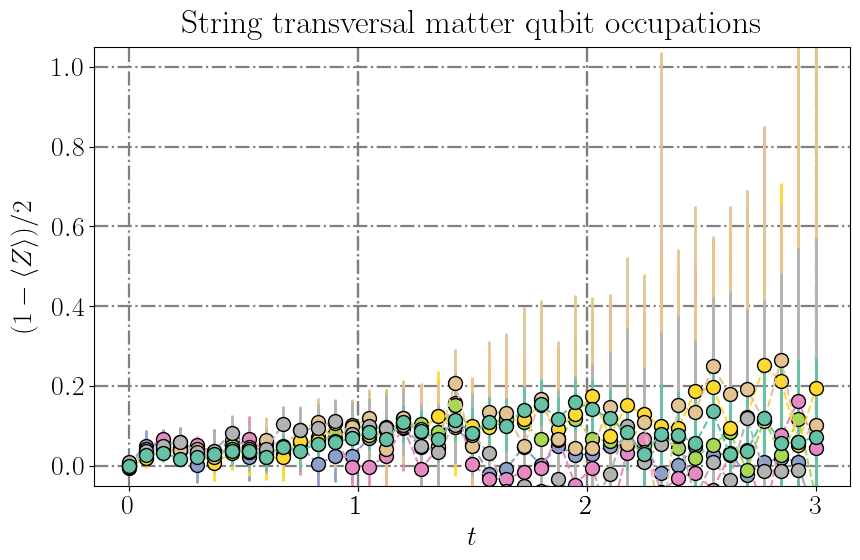

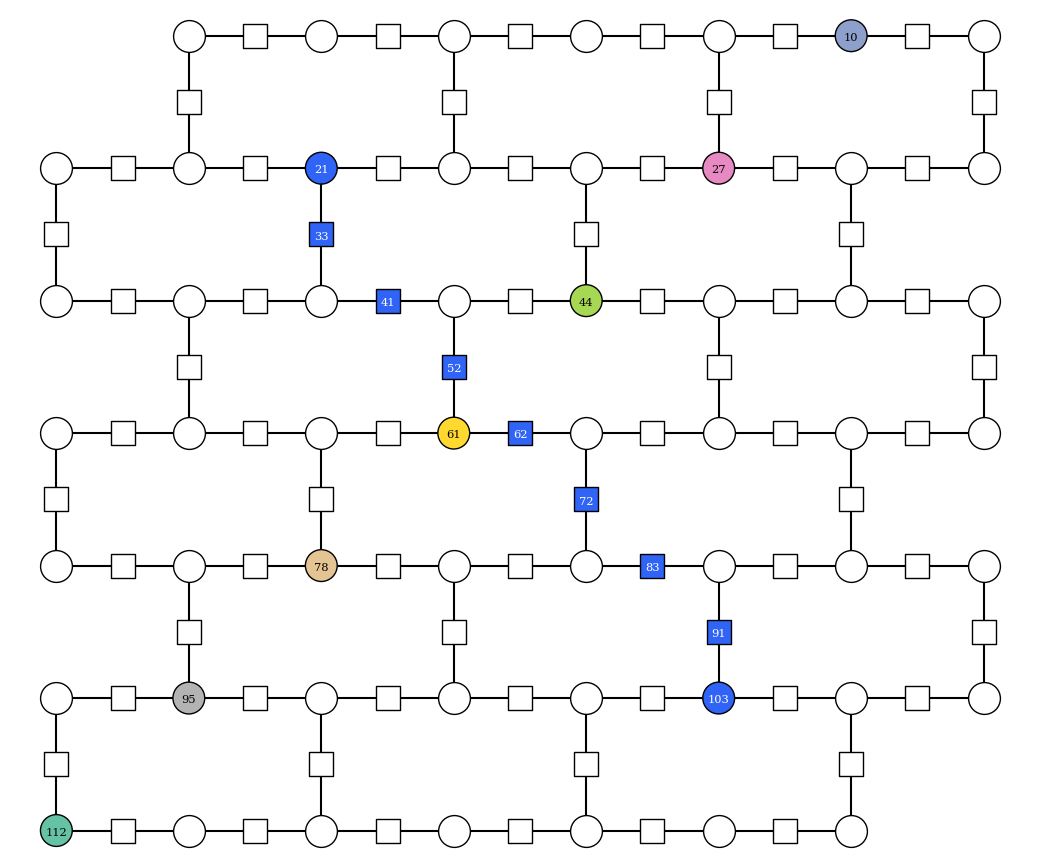

In [57]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt

cmap = lambda x: plt.get_cmap("Set2")((2+x)%8)
markers = None #["v", "^"]
title = "String transversal matter qubit occupations"
legend = False

# middle_qubit_coord = lattice.coords[string[len(string)//2]]
# complete_string_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string))
# transversal_matter_qubits = []
# for coords in complete_string_coords:
#     if not is_edge_coords(coords):
#         dx = coords[1] - middle_qubit_coord[1]
#         mirror_coords = (coords[0], middle_qubit_coord[1] - dx)
#         transversal_matter_qubits.append(lattice.coords_to_logical_qb(mirror_coords))

transversal_matter_qubits = [10, 27, 44, 61, 78, 95, 112]
sliced_observable = observables[0][:, transversal_matter_qubits]

plot_filepath = f"z2hex_quench_transversal_1_string_matter_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_transversal_1_string_matter_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"
clean_string = [qb for qb in string if qb not in transversal_matter_qubits]

confidence = (1 - observables_confidence[0][:, transversal_matter_qubits, :])/2

plot_individual_qubits_observable_evolution((1 - sliced_observable)/2, observable_confidence_matrix=confidence, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", markers=markers, y_lim=[-0.05, 1.05], title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(transversal_matter_qubits + clean_string, colors=[cmap(i) for i in range(len(transversal_matter_qubits))]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

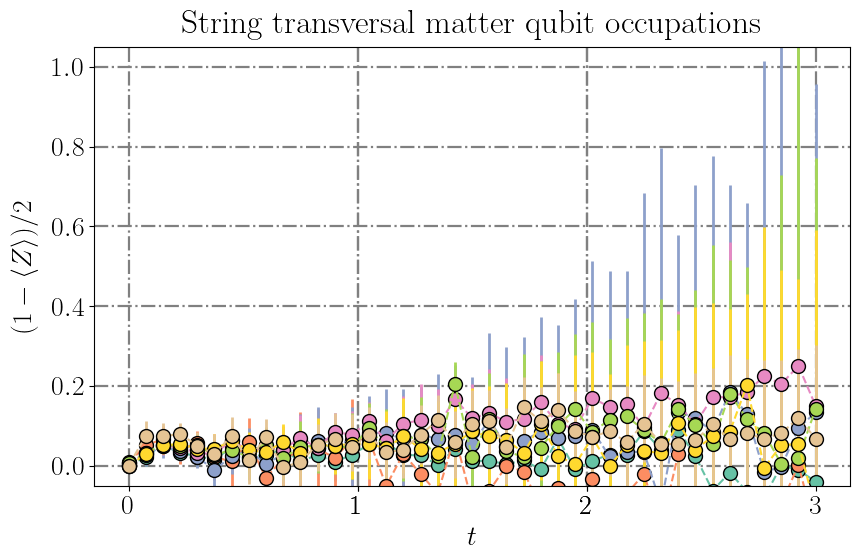

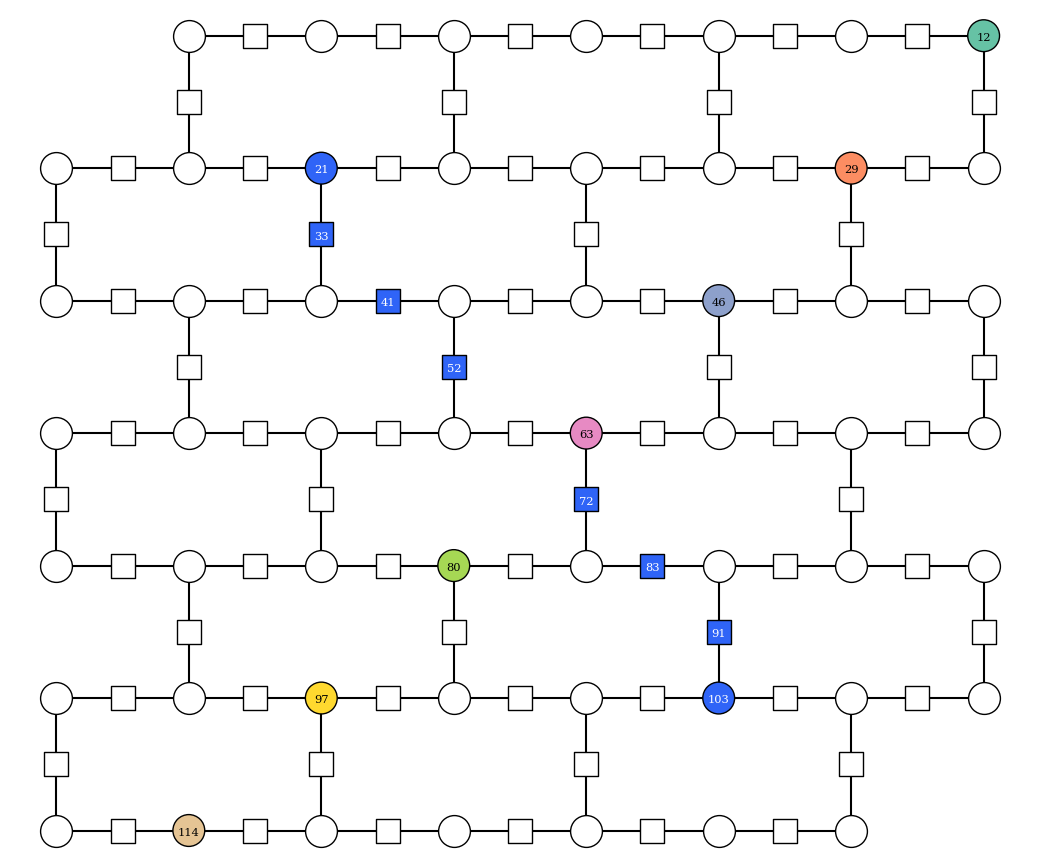

In [58]:
from utils.plotting import plot_individual_qubits_observable_evolution
from z2hex.geometry import array_of_coords_to_tuple, is_edge_coords
import matplotlib.pyplot as plt

cmap = lambda x: plt.get_cmap("Set2")(x)
markers = None #["v", "^"]
title = "String transversal matter qubit occupations"
legend = False

# middle_qubit_coord = lattice.coords[string[len(string)//2]]
# complete_string_coords = array_of_coords_to_tuple(lattice.complete_string_with_matter(string))
# transversal_matter_qubits = []
# for coords in complete_string_coords:
#     if not is_edge_coords(coords):
#         dx = coords[1] - middle_qubit_coord[1]
#         mirror_coords = (coords[0], middle_qubit_coord[1] - dx)
#         transversal_matter_qubits.append(lattice.coords_to_logical_qb(mirror_coords))

transversal_matter_qubits = [12, 29, 46, 63, 80, 97, 114]
sliced_observable = observables[0][:, transversal_matter_qubits]

plot_filepath = f"z2hex_quench_transversal_2_string_matter_qubits_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_transversal_2_string_matter_qubits_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"
clean_string = [qb for qb in string if qb not in transversal_gauge_qubits]

confidence = (1 - observables_confidence[0][:, transversal_matter_qubits, :])/2

plot_individual_qubits_observable_evolution((1 - sliced_observable)/2, observable_confidence_matrix=confidence, ylabel=r"$(1 - \langle Z \rangle)/2$", cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], markers=markers, title=title,  legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(transversal_matter_qubits + clean_string, colors=[cmap(i) for i in range(len(transversal_matter_qubits))]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

## Extremum oscillations

#### Top end (Gauge)

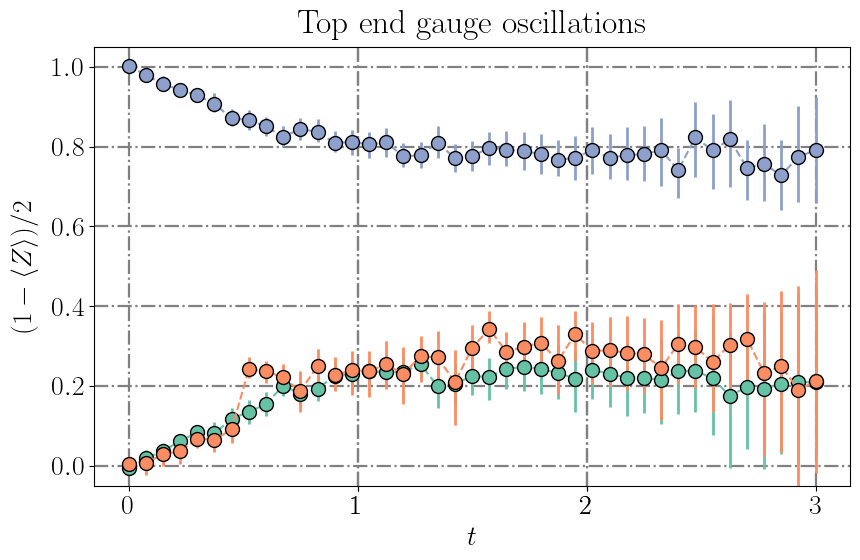

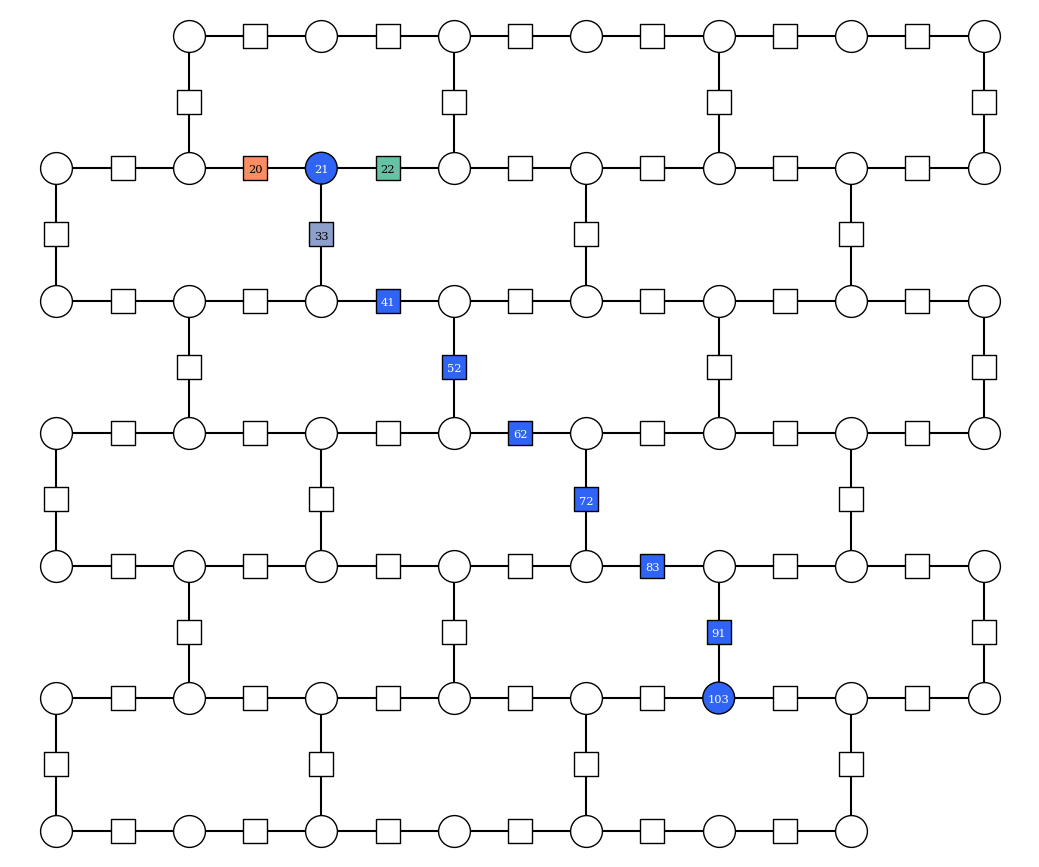

In [59]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Top end gauge oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0.5), (0, -0.5), (0.5, 0)]:
    candidate = string_qubit_coords[0] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)

to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_top_end_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_top_end_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Top end (Matter)

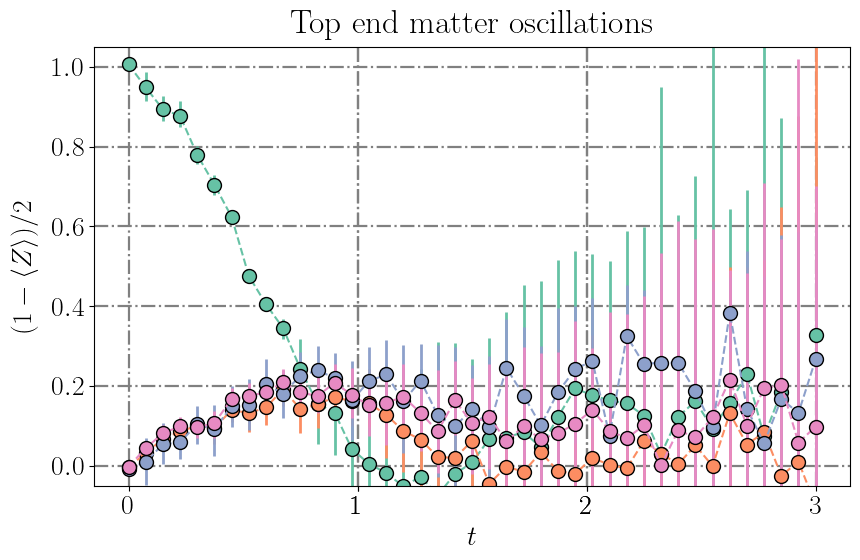

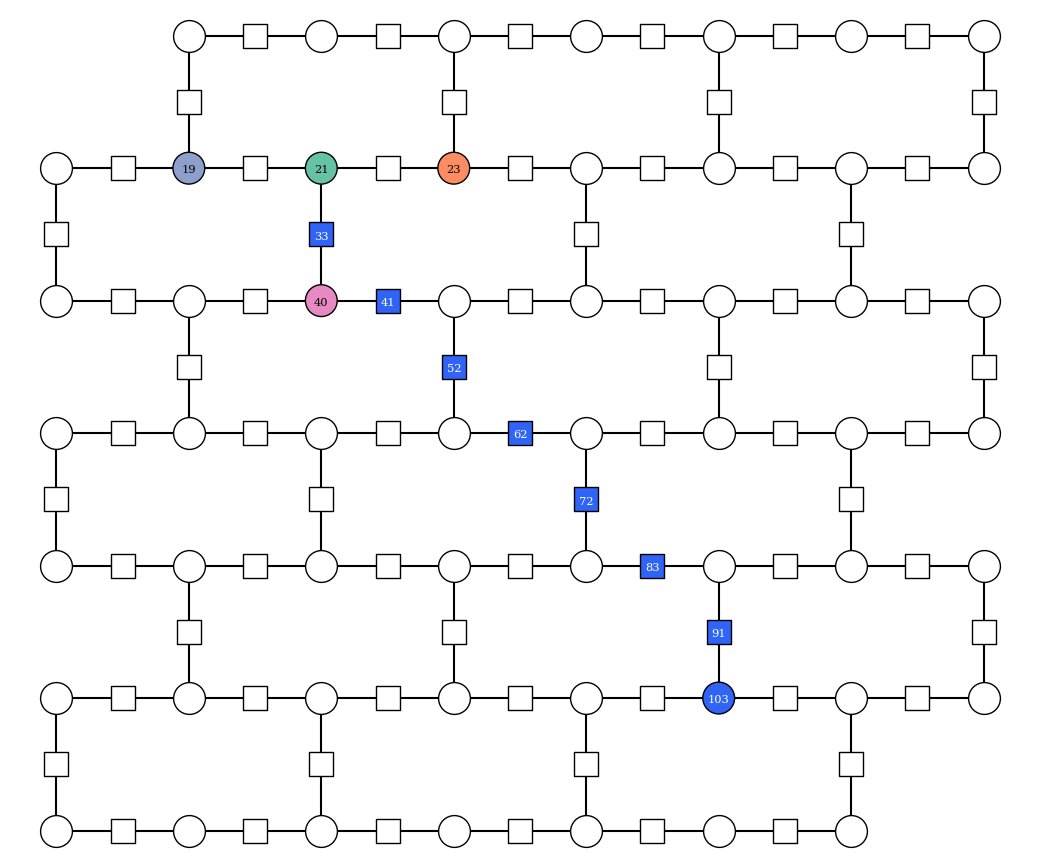

In [60]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Top end matter oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0), (0, 1), (0, -1), (1, 0)]:
    candidate = string_qubit_coords[0] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)

to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

# to_plot_qubit_inds = [25, 27, 29]

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_top_end_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_top_end_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2), cmap(3)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Bottom end (Gauge)

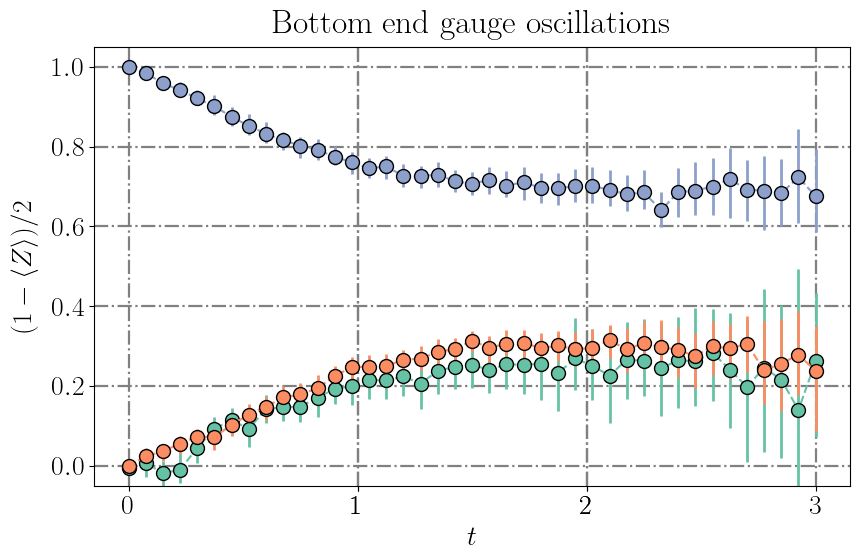

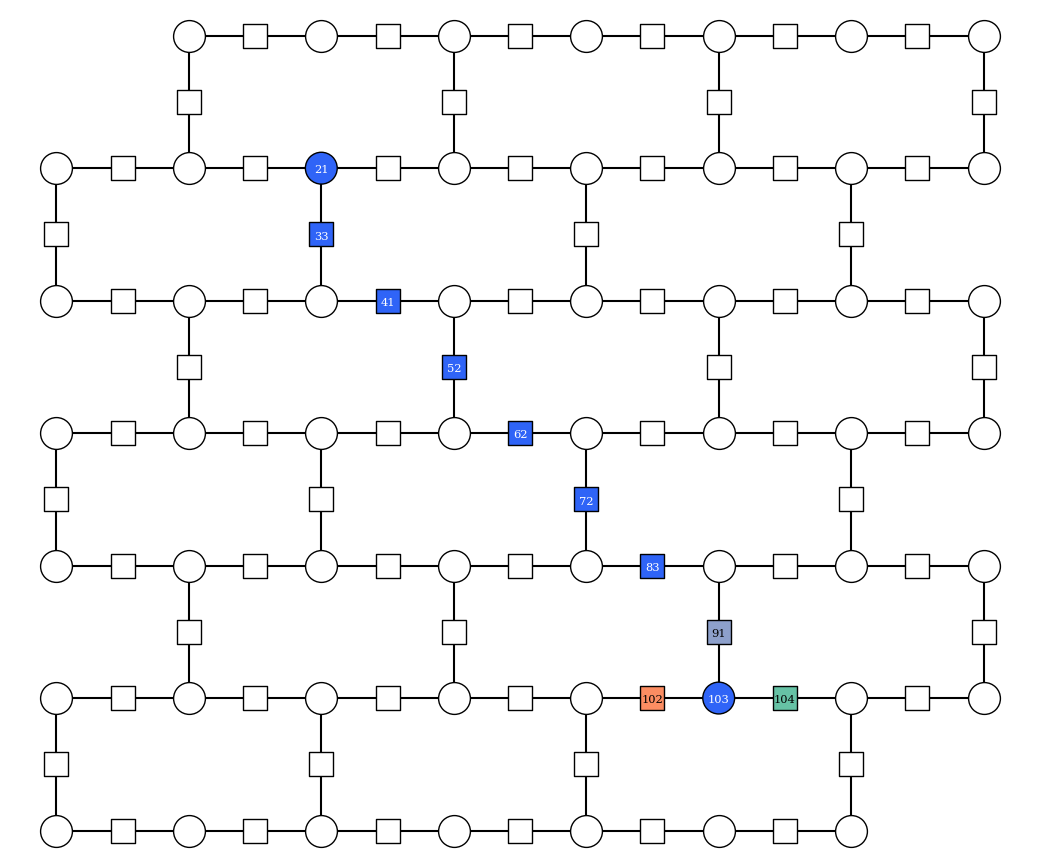

In [61]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Bottom end gauge oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0.5), (0, -0.5), (-0.5, 0)]:
    candidate = string_qubit_coords[-1] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)

to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

# to_plot_qubit_inds = [25, 27, 29]

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_bottom_end_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_bottom_end_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

#### Bottom end (Matter)

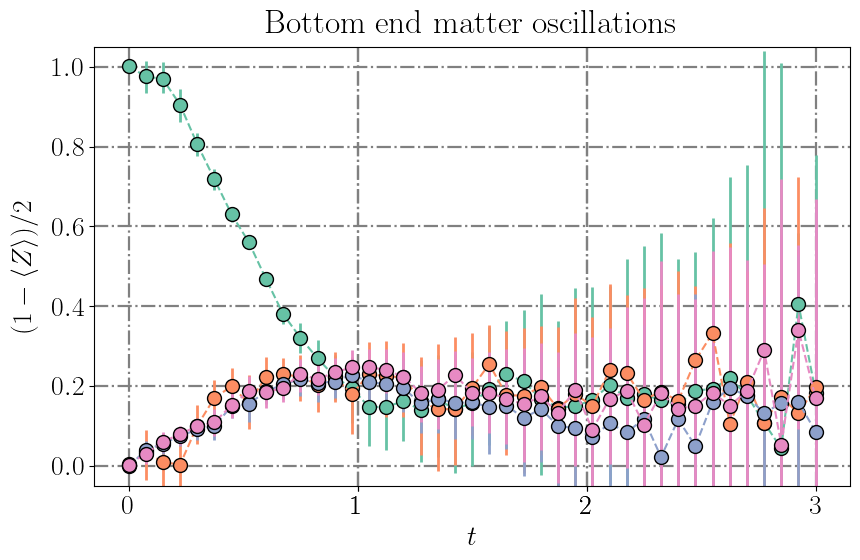

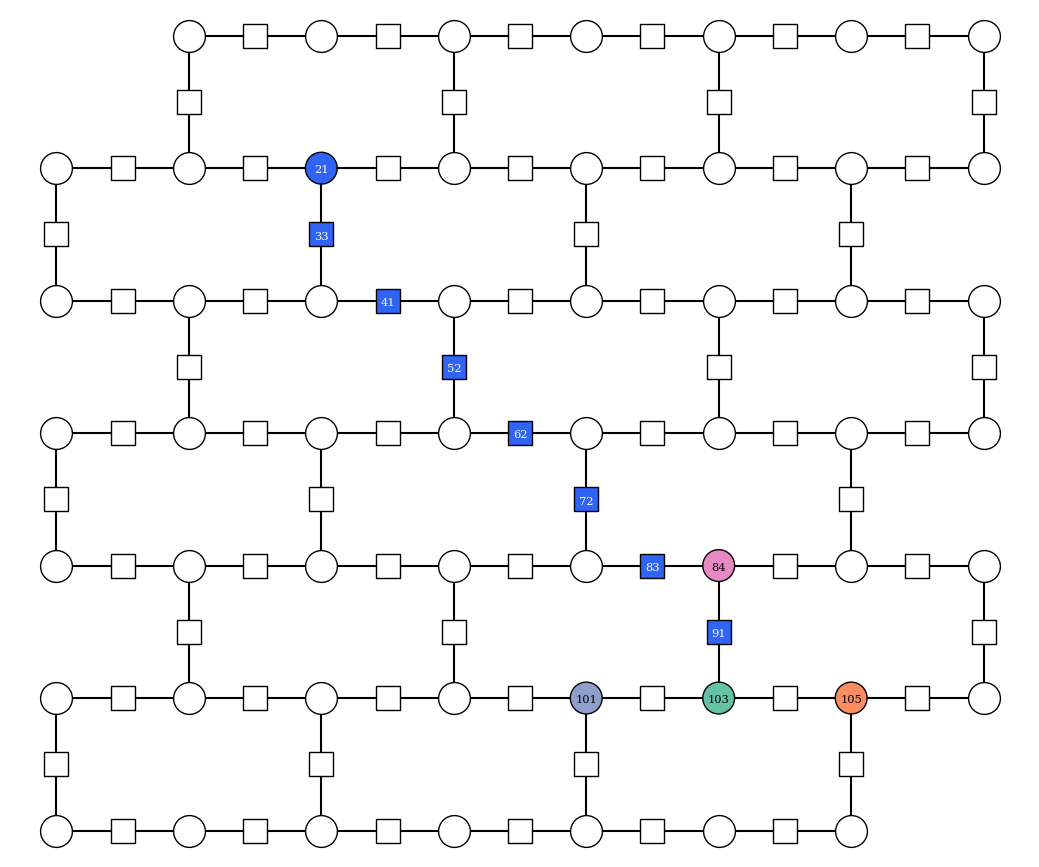

In [62]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Bottom end matter oscillations"
legend = False

string_qubit_coords = np.array(lattice.coords)[string]
to_plot_qubit_coord_candidates = []

for axisdir in [(0, 0), (0, 1), (0, -1), (-1, 0)]:
    candidate = string_qubit_coords[-1] + np.array(axisdir)
    if tuple(candidate.tolist()) in lattice.coords:
        to_plot_qubit_coord_candidates.append(candidate)
        
to_plot_qubit_inds = lattice.coords_to_logical_qb(to_plot_qubit_coord_candidates)

sliced_observable = observables[0][:, to_plot_qubit_inds]
sliced_observable_confidence = observables_confidence[0][:, to_plot_qubit_inds, :]
plot_filepath = f"z2hex_quench_bottom_end_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_bottom_end_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
funclabels = [r"$q_{%d}$" % i for i in to_plot_qubit_inds]

clean_string = [qb for qb in string if qb not in to_plot_qubit_inds]

plot_individual_qubits_observable_evolution((1-sliced_observable)/2, (1 - sliced_observable_confidence)/2, r"$(1 - \langle Z \rangle)/2$", cmap=cmap, markers=markers, x_ticks=x_ticks, x_label="$t$", y_lim=[-0.05, 1.05], funclabels=funclabels, title=title, legend=legend, filepath=plot_filepath)
lattice.plot_highlighted_qubits(to_plot_qubit_inds + clean_string, colors=[cmap(0), cmap(1), cmap(2), cmap(3)]+["#2f64f7"]*len(clean_string), filepath=legend_filepath)

## String plots

#### Left gauge covering plots

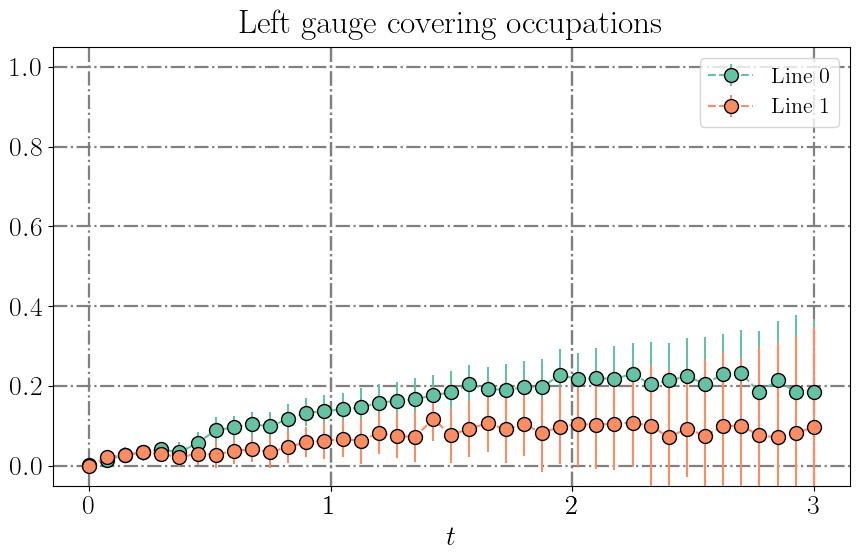

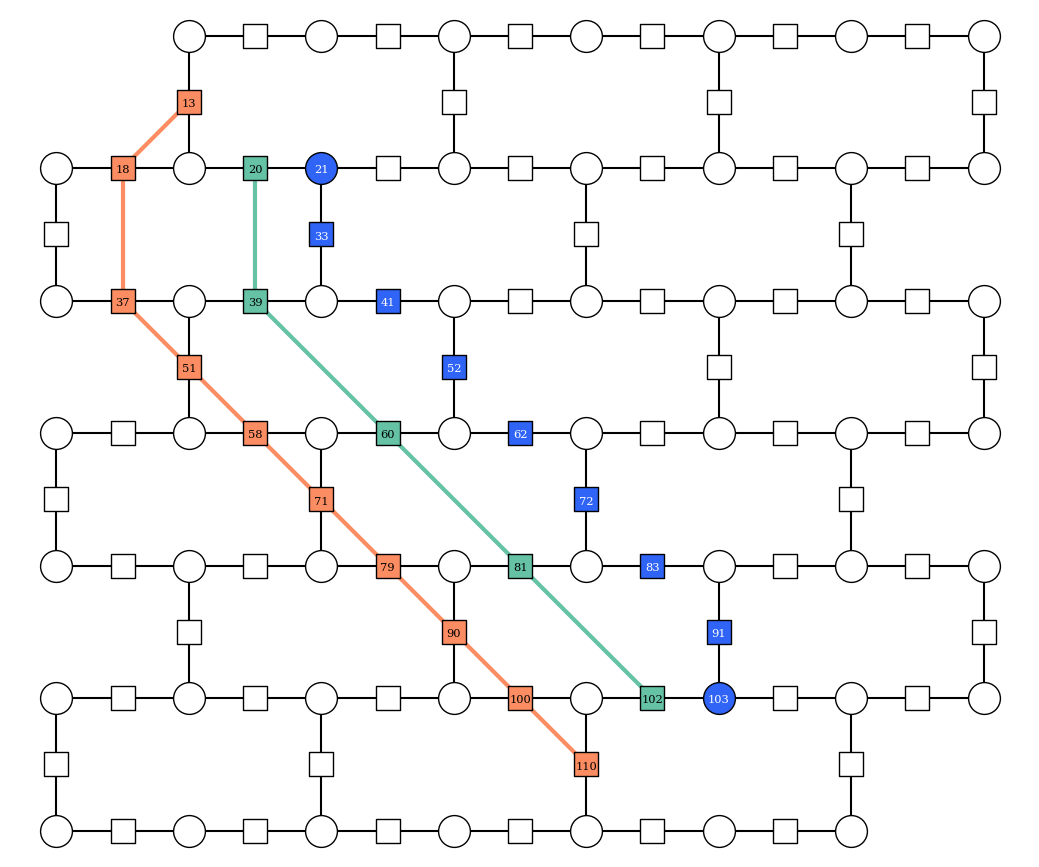

In [63]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Left gauge covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
qubits_to_average = []
for displacement in [-1, -2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            matter_reference = (scoords[0], scoords[1] + displacement + 1)
            candidates = [(matter_reference[0] - 0.5, matter_reference[1]), (matter_reference[0], matter_reference[1] - 0.5), (matter_reference[0] + 0.5, matter_reference[1])]
            for candidate in candidates:
                if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                    if len(this_displacement_coords) == 0:
                        this_displacement_coords.append(candidate)
                    else:
                        if candidate[0] not in [c[0] for c in this_displacement_coords]:
                            this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_left_cover_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_left_cover_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Right gauge covering plots

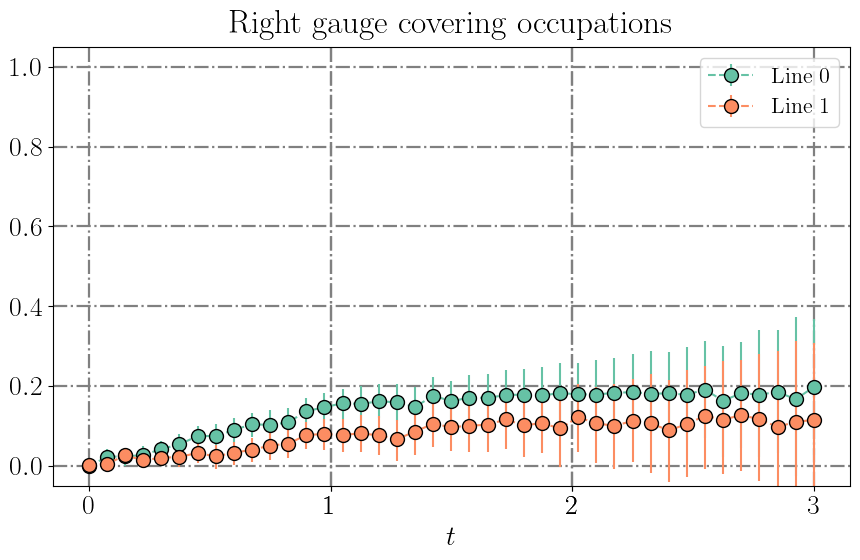

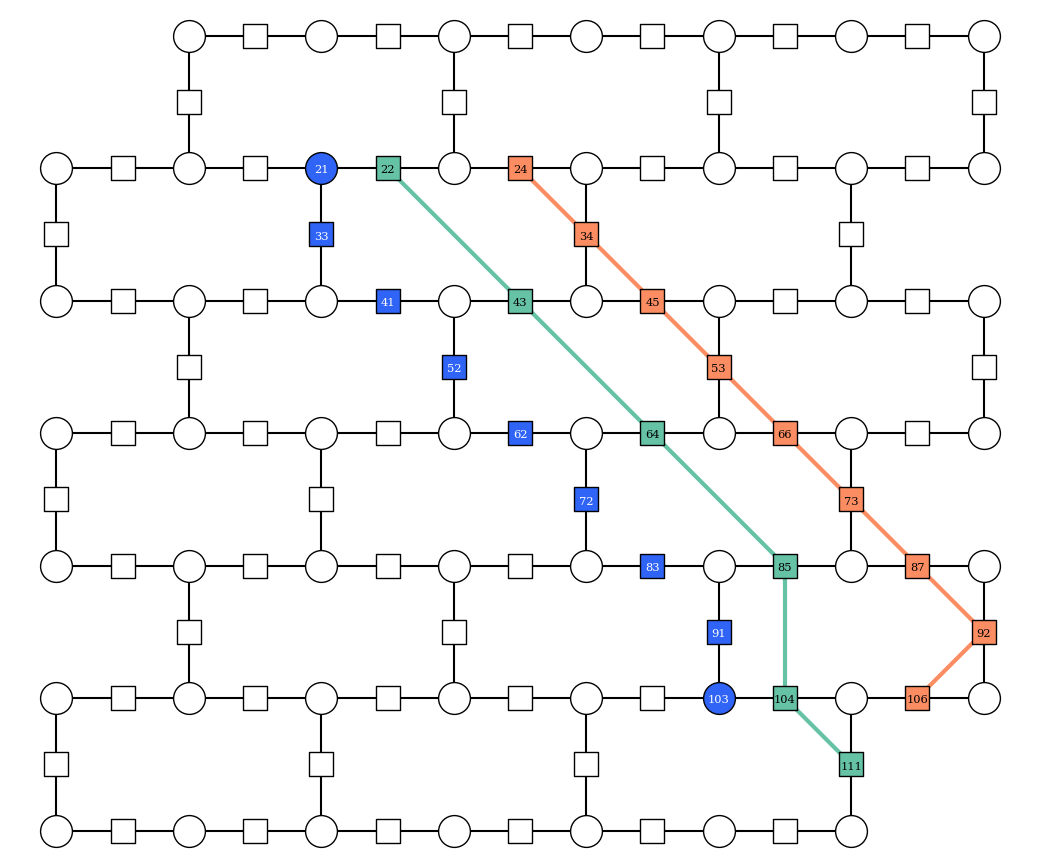

In [64]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = plt.get_cmap("Set2")
markers = None #["v", "^"]
title = "Right gauge covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [1, 2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            matter_reference = (scoords[0], scoords[1] + displacement)
            if (scoords[0], scoords[1] + 1) in complete_string_qubit_coords_tup:
                continue
            candidates = [(matter_reference[0], matter_reference[1] - 0.5), (matter_reference[0] + 0.5, matter_reference[1])]
            for candidate in candidates:
                if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                    if len(this_displacement_coords) == 0:
                        this_displacement_coords.append(candidate)
                    else:
                        if candidate[0] not in [c[0] for c in this_displacement_coords]:
                            this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_right_cover_gauge_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_right_cover_gauge_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Left matter covering plots

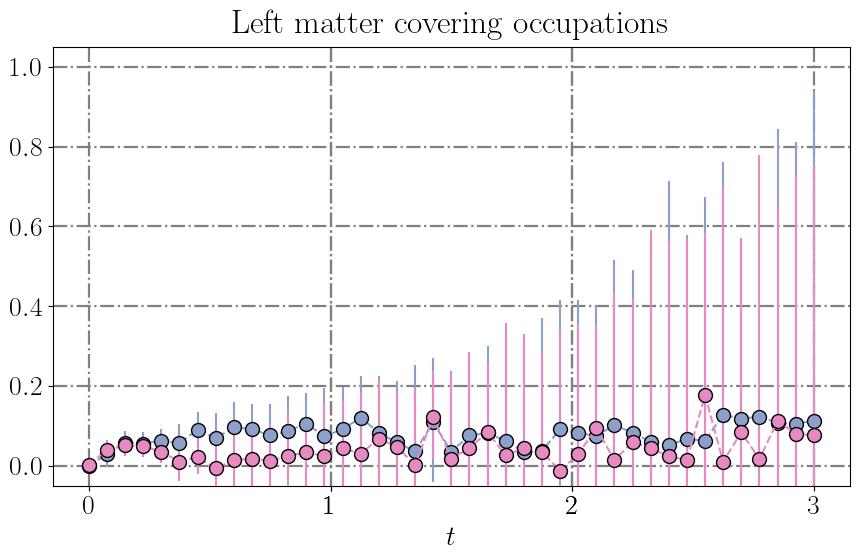

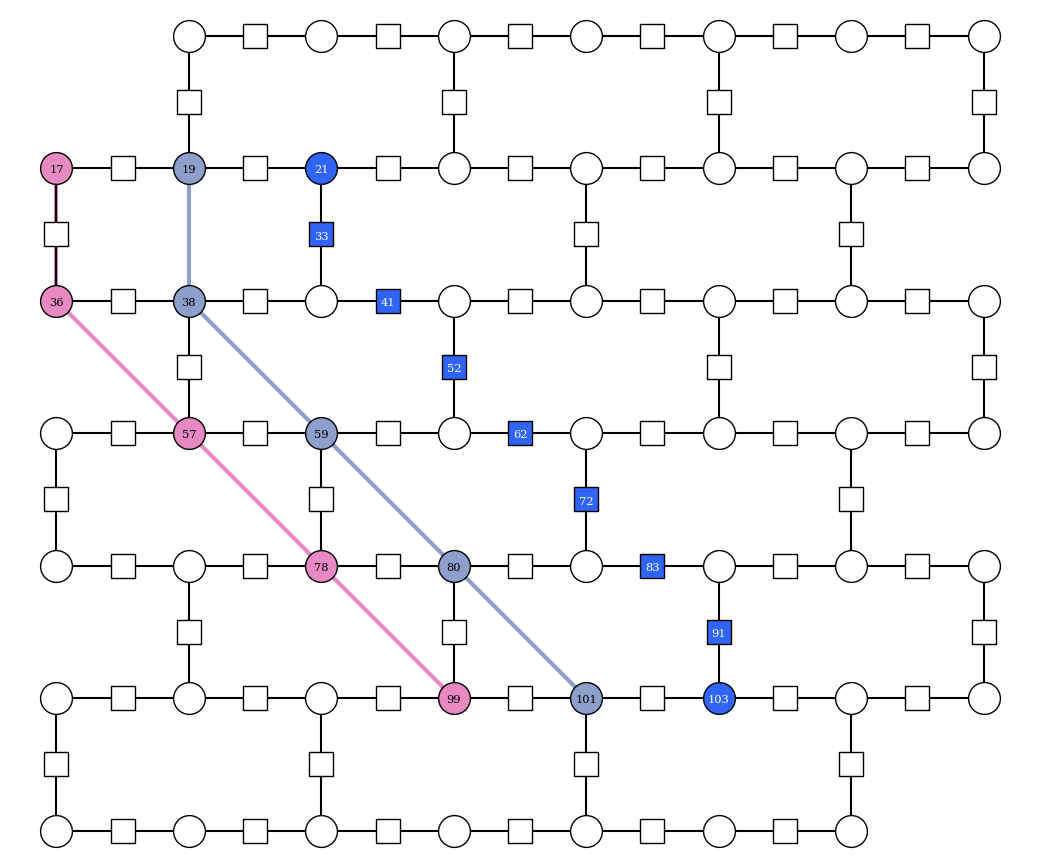

In [65]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Left matter covering occupations"
legend = False

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [-1, -2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            candidate = (scoords[0], scoords[1] + displacement)
            if candidate in complete_string_qubit_coords_tup:
                continue
            if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                if len(this_displacement_coords) == 0:
                    this_displacement_coords.append(candidate)
                else:
                    if candidate[0] not in [c[0] for c in this_displacement_coords]:
                        this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_left_cover_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_left_cover_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, legend=legend, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

#### Right matter covering plots

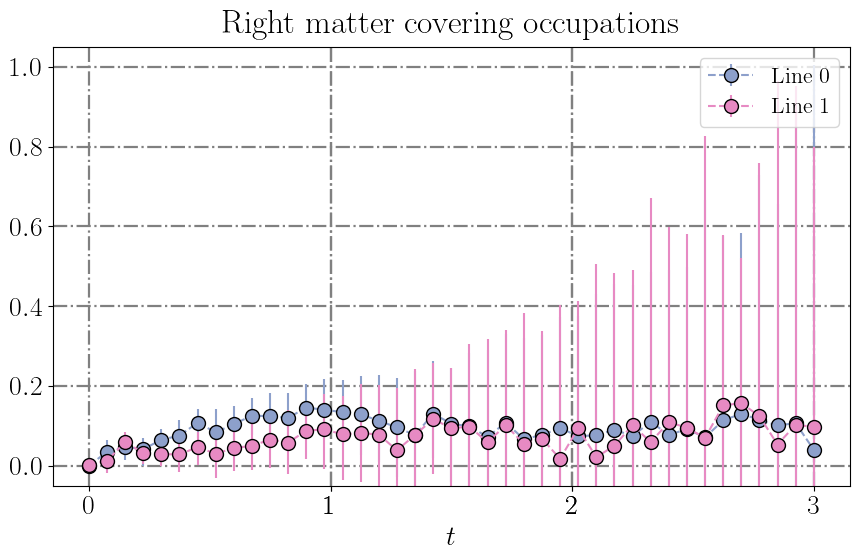

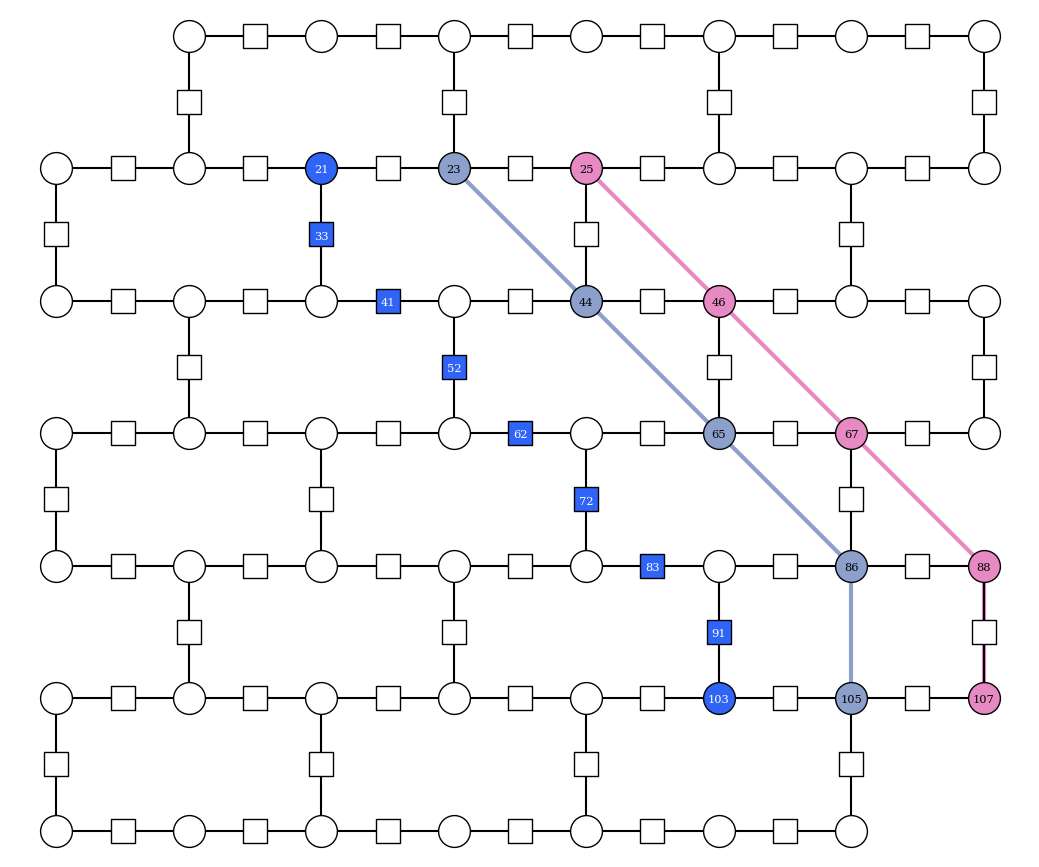

In [66]:
from utils.plotting import plot_average_qubits_observable_evolution
from z2hex.geometry import is_edge_coords, array_of_coords_to_tuple
import matplotlib.pyplot as plt
import numpy as np

cmap = lambda x: plt.get_cmap("Set2")(x+2)
markers = None #["v", "^"]
title = "Right matter covering occupations"

string_qubit_coords_arr = np.array(lattice.coords)[string]
string_qubit_coords_tup = array_of_coords_to_tuple(string_qubit_coords_arr)
complete_string_qubit_coords = lattice.complete_string_with_matter(string_qubit_coords_arr)
complete_string_qubit_coords_tup = array_of_coords_to_tuple(complete_string_qubit_coords)
qubits_to_average = []
for displacement in [1, 2]:
    this_displacement_coords = []
    for scoords in complete_string_qubit_coords:
        scoords = array_of_coords_to_tuple(scoords)
        if not is_edge_coords(scoords):
            candidate = (scoords[0], scoords[1] + displacement)
            if (scoords[0], scoords[1] + 1) in complete_string_qubit_coords_tup:
                continue
            if candidate in lattice.coords and (candidate not in string_qubit_coords_tup):
                if len(this_displacement_coords) == 0:
                    this_displacement_coords.append(candidate)
                else:
                    if candidate[0] not in [c[0] for c in this_displacement_coords]:
                        this_displacement_coords.append(candidate)
    qubits_to_average.append(lattice.coords_to_logical_qb(this_displacement_coords))

x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)
qubits_to_highlight = qubits_to_average + [string]

plot_filepath = f"z2hex_quench_right_cover_matter_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_right_cover_matter_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

plot_average_qubits_observable_evolution((1-observables[0])/2, qubits_to_average, observable_confidence_matrix=(1-observables_confidence[0])/2, markers=markers, cmap=cmap, x_ticks=x_ticks, x_label=r"$t$", y_lim=[-0.05, 1.05], title=title, filepath=plot_filepath)
lattice.plot_lines_of_qubits(qubits_to_highlight, colors=[cmap(0), cmap(1), "#2f64f7"], join_lines=[True, True, False], filepath=legend_filepath)

## Configuration counts plot

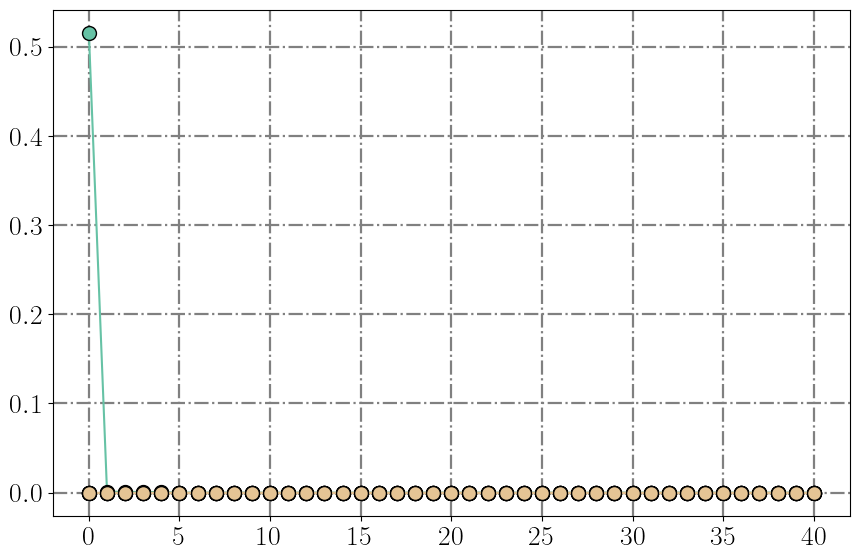

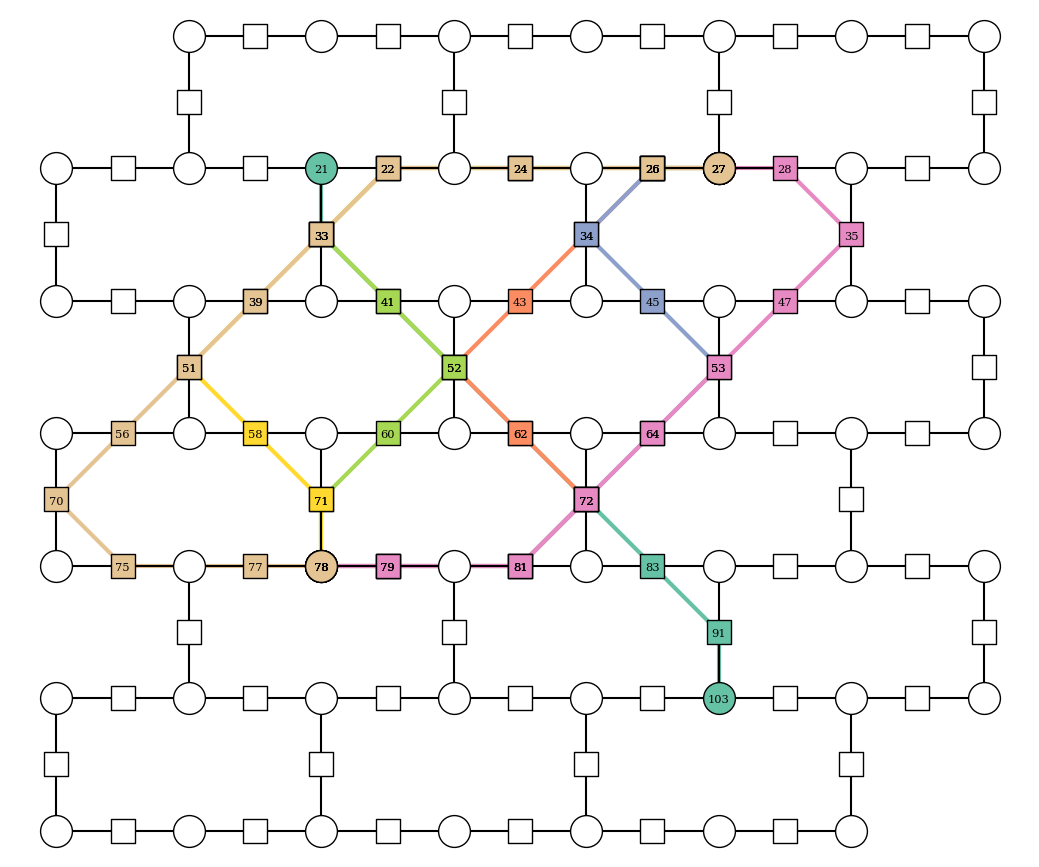

In [67]:
from z2hex.plotting import plot_configuration_sample_ratio
from utils.postselection import combine_samples_dicts
import matplotlib.pyplot as plt

string_configurations = [
    string,
    [27, 26, 34, 43, 52, 62, 72, 81, 79, 78],
    [27, 26, 34, 45, 53, 64, 72, 81, 79, 78],
    [27, 28, 35, 47, 53, 64, 72, 81, 79, 78],
    [27, 26, 24, 22, 33, 41, 52, 60, 71, 78],
    [27, 26, 24, 22, 33, 39, 51, 58, 71, 78],
    [27, 26, 24, 22, 33, 39, 51, 56, 70, 75, 77, 78]
]

cmap = plt.get_cmap("Set2")

clean_string = []
for qb in string:
    for string_config in string_configurations:
        if qb in string_config:
            break
    else:
        clean_string.append(qb)

combined_samples_dicts = []
for i in range(steps+1):
    all_layouts_postselected_samples = [postselected_samples_dicts[0][j][i] for j in range(len(circuits))]
    combined_samples_dicts.append(combine_samples_dicts(*all_layouts_postselected_samples))

plot_configuration_sample_ratio(lattice, combined_samples_dicts, string_configurations, cmap=cmap)
lattice.plot_lines_of_qubits(string_configurations + clean_string, colors=[cmap(i) for i in range(len(string_configurations))] + ["#2f64f7"]*len(clean_string))

# Noise mitigation plots

## # of flips

In [68]:
# from utils.postselection import combine_samples_dicts, initialize_postselection, get_logical_samples_dict
# from utils.plotting import plot_nflips_comparison

# job_index = 25

# postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

# all_layouts_samples_dicts = [samples_dicts[0][i][job_index] for i in range(len(circuits))]
# combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
# plot_nflips_comparison([combined_samples_dict], postselection_ops, [g], legend=False)

## Flip distribution mean

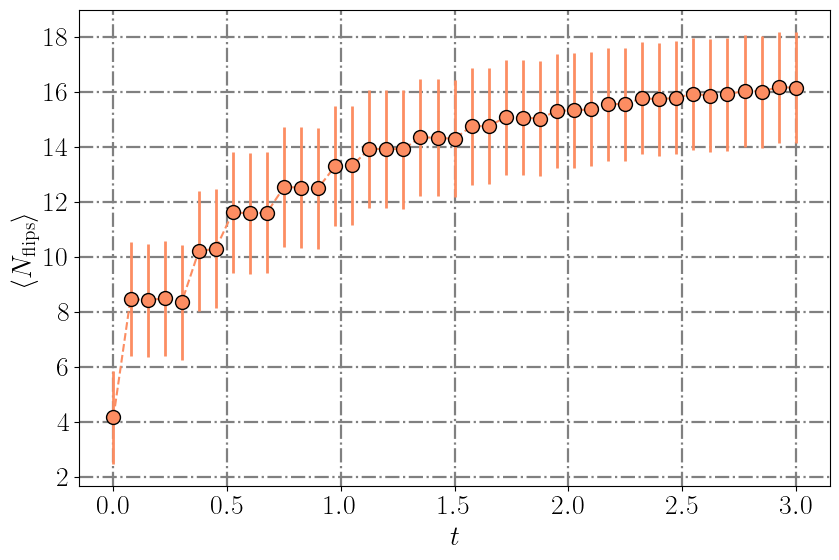

In [69]:
from utils.postselection import initialize_postselection, get_logical_samples_dict, combine_samples_dicts
import matplotlib.pyplot as plt
from pymatching import Matching

plot_filepath = f"z2hex_quench_nflips_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

postselection_mask = np.array([[int(str(opel) == basis) for opel in operator] for operator in postselection_ops])
decoder = Matching(postselection_mask)

distribution_means = np.zeros(steps+1)
standard_distributions = np.zeros(steps+1)
for i in range(steps+1):
    all_layouts_samples_dicts = [samples_dicts[0][j][i] for j in range(len(circuits))]
    combined_samples_dict = combine_samples_dicts(*all_layouts_samples_dicts)
    states = np.array([[int(c) for c in string] for string in combined_samples_dict.keys()])
    state_counts = np.array(list(combined_samples_dict.values()))
    states_syndromes = (states @ postselection_mask.T) % 2
    predicted_flips = decoder.decode_batch(states_syndromes)
    nflips = predicted_flips.sum(axis=1)
    unique_nflips = np.unique(nflips)
    this_flip_counts = {}
    this_total_nflips = 0
    for nf in unique_nflips:
        this_counts = np.sum(state_counts[np.equal(nflips, nf)])
        this_flip_counts[nf] = this_counts
        this_total_nflips += this_counts
    this_mean = 0
    for nf, counts in this_flip_counts.items():
        this_mean += nf*counts/this_total_nflips
    distribution_means[i] = this_mean
    for nf, counts in this_flip_counts.items():
        standard_distributions[i] += (nf - this_mean)**2 * counts/this_total_nflips
    standard_distributions[i] = np.sqrt(standard_distributions[i])

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])

x = np.linspace(0, final_time, steps+1)
x_ticks = np.round(np.linspace(0, final_time, 6)).astype(int)

plt.errorbar(x, distribution_means, yerr=standard_distributions, fmt="o--", color=plt.get_cmap("Set2")(1), markersize=10, elinewidth=2, markeredgecolor="black")
plt.xlabel(r"$t$")
plt.ylabel(r"$\langle N_{\mathrm{flips}} \rangle$")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.tight_layout()
plt.savefig(plot_filepath)
plt.rcdefaults()

# Auxiliar observables cells

In [70]:
from utils.postselection import initialize_postselection

postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(len(lattice), postselection_operators_func, observable_generating_funcs)

In [71]:
from utils.postselection import combine_samples_dicts

all_layouts_postselected_samples = [postselected_samples_dicts[0][i][25] for i in range(len(circuits))]
combined_postselected_samples = combine_samples_dicts(*all_layouts_postselected_samples)

all_layouts_odr_postselected_samples = [postselected_samples_dicts[1][i][25] for i in range(len(circuits))]
combined_odr_postselected_samples = combine_samples_dicts(*all_layouts_odr_postselected_samples)

In [72]:
from utils.postselection import measure_diagonal_observables

real_observables, real_observables_confidence = measure_diagonal_observables(combined_postselected_samples, diagonal_observables, confidence=0.6)
odr_observables, odr_observables_confidence = measure_diagonal_observables(combined_odr_postselected_samples, diagonal_observables, confidence=0.6)

In [73]:
from utils.odr import compute_depolarizing_probability, renormalize_observable

p_arr = compute_depolarizing_probability(odr_observables, 1, 0, odr_circuits[0][0].num_qubits)
clean_expectation_values, clean_expectation_values_confidence = renormalize_observable(real_observables, p_arr, 0, circuits[0][0].num_qubits, [-1, 1], expected_observable_arr=1, observable_confidence=real_observables_confidence)

In [74]:
((1-clean_expectation_values)/2)[27]

0.06897111008488788

In [75]:
clean_expectation_values.shape

(125,)

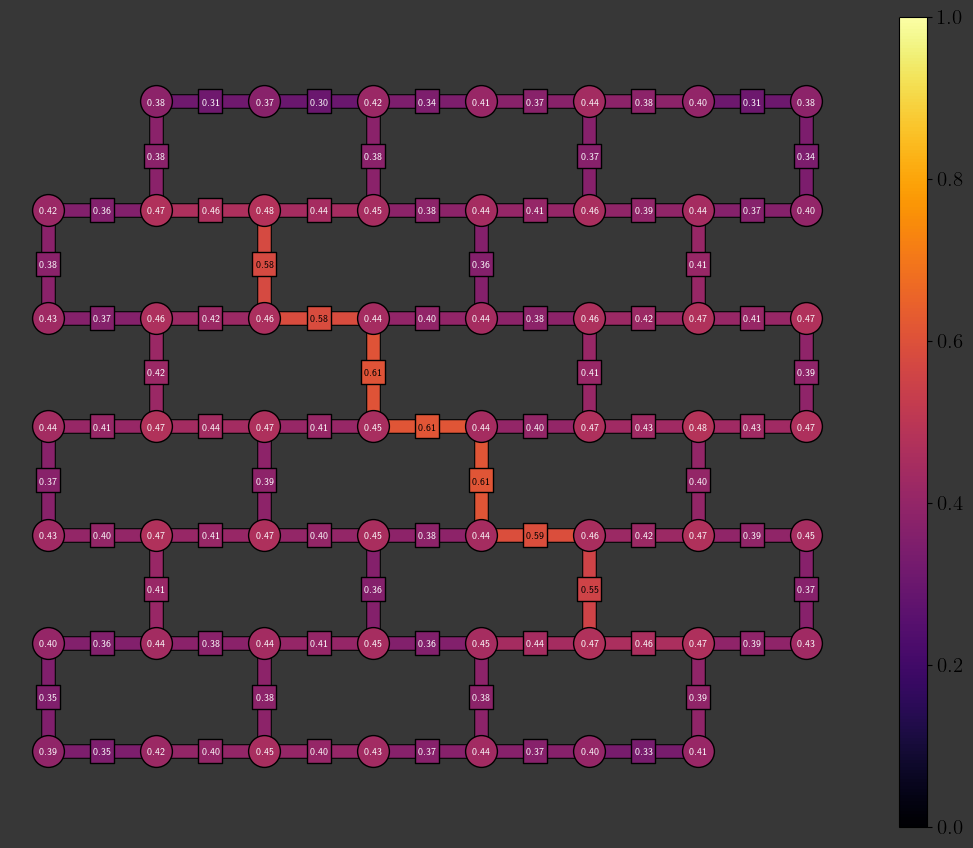

In [76]:
from z2hex.plotting import local_observable_plot

local_observable_plot(((1-real_observables)/2), lattice, dark_theme=True, cmap_range=[0, 1])

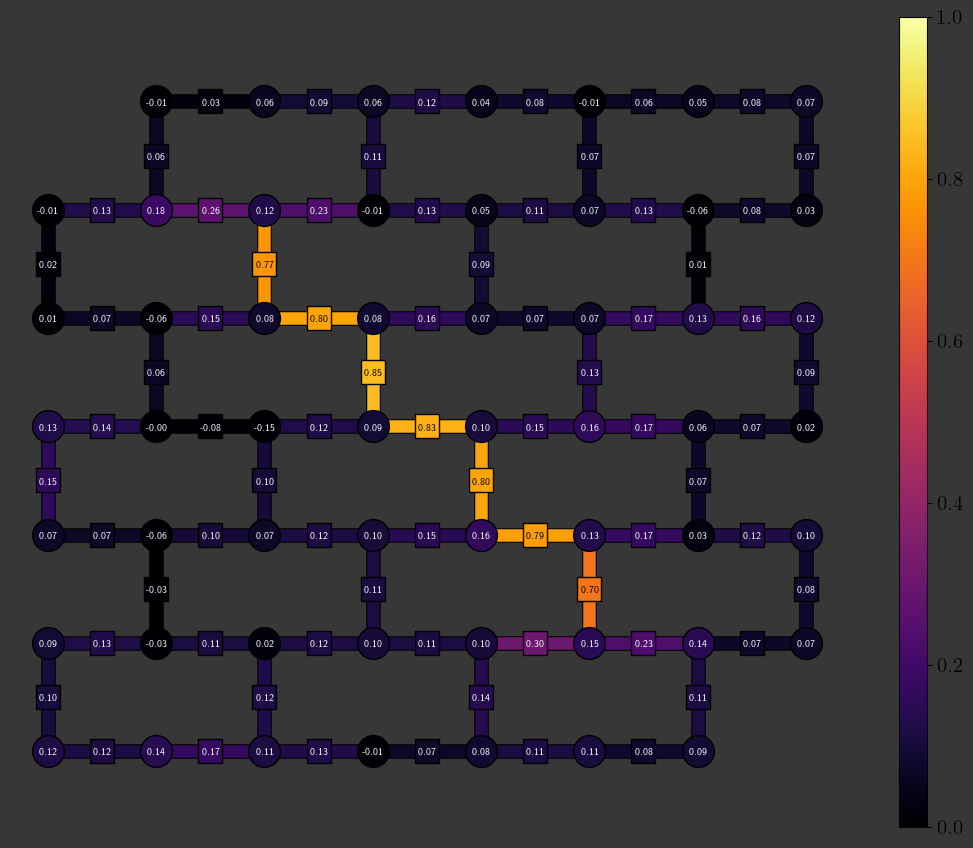

In [77]:
from z2hex.plotting import local_observable_plot

local_observable_plot(((1-clean_expectation_values)/2), lattice, dark_theme=True, cmap_range=[0, 1])

In [78]:
max(combined_postselected_samples.values())

1